In [2]:
# ============================================================
# Reverse cross-dataset eval setup:
# Train on DF40 checkpoints -> Test on WildDeepfake test split
#
# Creates:
#   outputs_reverse_cross_dataset_df40_to_wilddeepfake/
#     manifests/
#     checkpoint_inventory.csv
#     run_reverse_eval_commands.sh
#
# Does not retrain anything.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import shlex
import os
import re
import subprocess
import time

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")

REVERSE_ROOT = PROJECT_ROOT / "outputs_reverse_cross_dataset_df40_to_wilddeepfake"
MANIFEST_DIR = REVERSE_ROOT / "manifests"
LOG_DIR = REVERSE_ROOT / "logs"
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

WILD_CANONICAL = PROJECT_ROOT / "outputs_wilddeepfake/wilddeepfake_manifest_canonical.csv"

# Output manifests
WILD_TEST_MASTER = MANIFEST_DIR / "wilddeepfake_test_manifest_master.csv"
WILD_TEST_EVAL_COMPAT = MANIFEST_DIR / "wilddeepfake_test_manifest_eval_compat.csv"
WILD_TEST_FREQDEBIAS = MANIFEST_DIR / "wilddeepfake_test_manifest_freqdebias_safe.csv"
WILD_TEST_GEND = MANIFEST_DIR / "wilddeepfake_test_manifest_gend_safe.csv"
WILD_TEST_AGRFN = MANIFEST_DIR / "wilddeepfake_test_manifest_agrfn_safe.csv"
WILD_TEST_DFDHR = MANIFEST_DIR / "wilddeepfake_test_manifest_dfdhr_safe.csv"
WILD_TEST_ADAGATE = MANIFEST_DIR / "wilddeepfake_test_manifest_adagate_repo_compat.csv"

CHECKPOINT_INVENTORY = REVERSE_ROOT / "checkpoint_inventory_df40_trained.csv"
COMMAND_SCRIPT = REVERSE_ROOT / "run_reverse_eval_commands.sh"

FRAMES_PER_VIDEO = 32
SEED = 42

print("=" * 100)
print("1. Build WildDeepfake test manifests")
print("=" * 100)

if not WILD_CANONICAL.exists():
    raise FileNotFoundError(WILD_CANONICAL)

df = pd.read_csv(WILD_CANONICAL)
df = df.loc[:, ~df.columns.duplicated()].copy()

if "split" not in df.columns:
    raise ValueError("WildDeepfake canonical manifest has no split column.")

df["split"] = df["split"].astype(str).str.lower()

if "frame_path" in df.columns:
    path_col = "frame_path"
elif "image_path" in df.columns:
    path_col = "image_path"
else:
    raise ValueError(f"No frame_path or image_path column found. Columns: {list(df.columns)}")

if "video_id" in df.columns:
    video_col = "video_id"
elif "group_id" in df.columns:
    video_col = "group_id"
elif "sample_unit_id" in df.columns:
    video_col = "sample_unit_id"
else:
    video_col = None

test_df = df[df["split"] == "test"].copy()
if len(test_df) == 0:
    raise RuntimeError("No WildDeepfake test rows found.")

base = pd.DataFrame({
    "frame_path": test_df[path_col].astype(str),
    "label": test_df["label"].astype(int),
    "label_name": test_df["label"].astype(int).map({0: "real", 1: "fake"}),
    "split": "test",
})

if video_col:
    base["video_id"] = test_df[video_col].astype(str).values
else:
    base["video_id"] = base["frame_path"].map(lambda x: str(Path(x).parent))

base["group_id"] = base["video_id"].astype(str)
base["sample_unit_id"] = base["video_id"].astype(str)

if "method" in test_df.columns:
    base["method"] = test_df["method"].astype(str).values
else:
    base["method"] = "WildDeepfake"

base["dataset"] = "WildDeepfake"
base["dataset_name"] = "WildDeepfake"
base["domain"] = "WildDeepfake"

# Drop missing files.
exists_mask = base["frame_path"].map(lambda p: isinstance(p, str) and Path(p).exists())
missing = int((~exists_mask).sum())
print("Missing test frame paths:", missing)
base = base[exists_mask].copy()

# Sample 32 frames per video.
parts = []
for _, g in base.groupby("video_id", sort=False):
    g = g.sort_values("frame_path").reset_index(drop=True)
    if len(g) <= FRAMES_PER_VIDEO:
        parts.append(g)
    else:
        idx = np.linspace(0, len(g) - 1, FRAMES_PER_VIDEO).astype(int)
        parts.append(g.iloc[idx])

wild_test = pd.concat(parts, ignore_index=True)

# Master test-only manifest.
wild_test.to_csv(WILD_TEST_MASTER, index=False)

# Some scripts require train/val/test splits even in eval mode.
# We add tiny dummy train/val rows but preserve the true WildDeepfake test rows.
rng = np.random.default_rng(SEED)
real_rows = wild_test[wild_test["label"] == 0]
fake_rows = wild_test[wild_test["label"] == 1]

dummy_parts = []
for split_name in ["train", "val"]:
    for sdf in [real_rows, fake_rows]:
        n = min(16, len(sdf))
        if n > 0:
            sampled = sdf.sample(n=n, random_state=SEED).copy()
            sampled["split"] = split_name
            dummy_parts.append(sampled)

eval_compat = pd.concat(dummy_parts + [wild_test], ignore_index=True)
eval_compat.to_csv(WILD_TEST_EVAL_COMPAT, index=False)

# Model-specific safe manifests.
wild_test.to_csv(WILD_TEST_AGRFN, index=False)
wild_test.to_csv(WILD_TEST_DFDHR, index=False)

# GenD/FreqDebias scripts rename frame_path -> image_path internally, so do not include image_path.
wild_test.drop(columns=["image_path"], errors="ignore").to_csv(WILD_TEST_FREQDEBIAS, index=False)
wild_test.drop(columns=["image_path"], errors="ignore").to_csv(WILD_TEST_GEND, index=False)

# AdaGate repo-compatible: frame_path + label_name, no image_path.
adagate_df = wild_test[
    ["frame_path", "label", "label_name", "split", "video_id", "method", "dataset", "dataset_name", "domain"]
].copy()
adagate_df.to_csv(WILD_TEST_ADAGATE, index=False)

print("Saved:", WILD_TEST_MASTER)
print("Saved:", WILD_TEST_EVAL_COMPAT)
print("Saved:", WILD_TEST_FREQDEBIAS)
print("Saved:", WILD_TEST_GEND)
print("Saved:", WILD_TEST_AGRFN)
print("Saved:", WILD_TEST_DFDHR)
print("Saved:", WILD_TEST_ADAGATE)

print("\nWildDeepfake test distribution after 32fpv sampling:")
print("Rows:", len(wild_test))
print("Videos:", wild_test["video_id"].nunique())
display(pd.crosstab(wild_test["split"], wild_test["label"]))

print("\n" + "=" * 100)
print("2. Discover DF40-trained checkpoints")
print("=" * 100)

checkpoint_rows = []

for p in PROJECT_ROOT.rglob("*"):
    if not p.is_file():
        continue

    name = p.name.lower()
    full = str(p).lower()

    if p.suffix.lower() not in [".pt", ".pth", ".ckpt"]:
        continue

    if ".ipynb_checkpoints" in full:
        continue

    # We only want likely DF40-trained checkpoints.
    if "df40" not in full:
        continue

    model = "unknown"
    if "agrfn" in full or "grfn" in full:
        model = "A-GRFN"
    elif "gend" in full:
        model = "GenD"
    elif "freq" in full or "debias" in full:
        model = "FreqDebias"
    elif "dfdhr" in full or "dfd-hr" in full or "dfd_hr" in full:
        model = "DFD-HR"
    elif "adagate" in full or "gated_dual" in full:
        model = "AdaGate"

    priority = 0
    if "best" in name:
        priority += 100
    if "checkpoint" in name:
        priority += 20
    if "latest" in name:
        priority += 5
    if "wilddeepfake" in full:
        priority -= 100

    checkpoint_rows.append({
        "model_guess": model,
        "priority": priority,
        "path": str(p),
        "name": p.name,
        "parent": str(p.parent),
        "size_mb": round(p.stat().st_size / 1024**2, 3),
        "modified": pd.to_datetime(p.stat().st_mtime, unit="s"),
    })

inventory = pd.DataFrame(checkpoint_rows)

if len(inventory):
    inventory = inventory.sort_values(["model_guess", "priority", "modified"], ascending=[True, False, False])
    inventory.to_csv(CHECKPOINT_INVENTORY, index=False)
    print("Saved checkpoint inventory:", CHECKPOINT_INVENTORY)
    display(inventory)
else:
    print("No DF40 checkpoint candidates found.")
    inventory = pd.DataFrame(columns=["model_guess", "path"])

def choose_checkpoint(model_name, preferred_keywords):
    if len(inventory) == 0:
        return None

    sub = inventory[inventory["model_guess"].eq(model_name)].copy()

    if len(sub) == 0:
        return None

    # Give extra priority for preferred output names.
    def extra_score(path):
        s = str(path).lower()
        score = 0
        for kw in preferred_keywords:
            if kw.lower() in s:
                score += 10
        return score

    sub["extra"] = sub["path"].map(extra_score)
    sub = sub.sort_values(["extra", "priority", "modified"], ascending=[False, False, False])

    return Path(sub.iloc[0]["path"])

selected = {
    "A-GRFN": choose_checkpoint("A-GRFN", ["outputs_agrfn_df40", "adaptive", "best_checkpoint"]),
    "GenD": choose_checkpoint("GenD", ["outputs_gend_df40", "best_checkpoint", "best"]),
    "FreqDebias": choose_checkpoint("FreqDebias", ["outputs_freqdebias_df40", "freqdebias_latest", "freqdebias_best"]),
    "DFD-HR": choose_checkpoint("DFD-HR", ["outputs_dfdhr_df40", "latest_checkpoint", "best"]),
    "AdaGate": choose_checkpoint("AdaGate", ["outputs_adagate_df40_indomain", "best_gated_dual_branch_df40"]),
}

print("\nSelected checkpoint guesses:")
for model, path in selected.items():
    print(f"{model:12s}: {path if path else 'NOT FOUND'}")

print("\n" + "=" * 100)
print("3. Write eval command script")
print("=" * 100)

def q(x):
    return shlex.quote(str(x))

commands = []
commands.append("#!/usr/bin/env bash")
commands.append("set -e")
commands.append("")
commands.append(f"PROJECT_ROOT={q(PROJECT_ROOT)}")
commands.append("cd \"$PROJECT_ROOT\"")
commands.append("")

# A-GRFN / GRFN adaptive routing.
if selected["A-GRFN"]:
    out = REVERSE_ROOT / "agrfn_df40_to_wilddeepfake"
    log = LOG_DIR / "agrfn_df40_to_wilddeepfake.log"
    cmd = f"""
python -u agrfn_adaptive_routing_df40.py \\
  --metadata_csv {q(WILD_TEST_EVAL_COMPAT)} \\
  --out_dir {q(out)} \\
  --dataset_name WildDeepfake \\
  --resume {q(selected["A-GRFN"])} \\
  --eval_only \\
  --path_col frame_path \\
  --label_col label \\
  --split_col split \\
  --group_col video_id \\
  --skip_path_check \\
  --fusion_mode adaptive_film \\
  --streams rgb,fingerprint,jpeg,freq \\
  --frames_per_video 32 \\
  --image_size 224 \\
  --batch_size 16 \\
  --num_workers 2 \\
  --feat_dim 128 \\
  --threshold_metric balanced_accuracy \\
  --uncertainty_threshold 0.50 \\
  --score_direction normal \\
  --seed 42 \\
  --amp \\
  > {q(log)} 2>&1
"""
    commands.append("echo 'Running A-GRFN DF40 -> WildDeepfake'")
    commands.append(cmd.strip())
    commands.append("")

# GenD.
# Assumes your gend_reimpl_ffpp.py supports --resume and eval-only or zero-epoch evaluation.
if selected["GenD"]:
    out = REVERSE_ROOT / "gend_df40_to_wilddeepfake"
    log = LOG_DIR / "gend_df40_to_wilddeepfake.log"
    cmd = f"""
python -u gend_reimpl_ffpp.py \\
  --metadata_csv {q(WILD_TEST_EVAL_COMPAT)} \\
  --out_dir {q(out)} \\
  --resume {q(selected["GenD"])} \\
  --eval_only \\
  --image_size 224 \\
  --frames_per_video 32 \\
  --batch_size 16 \\
  --num_workers 2 \\
  --amp \\
  > {q(log)} 2>&1
"""
    commands.append("echo 'Running GenD DF40 -> WildDeepfake'")
    commands.append(cmd.strip())
    commands.append("")

# FreqDebias.
# This script has no eval_only in the version we inspected, so use:
# --resume + --skip_pretrain + --freqdebias_epochs 0
if selected["FreqDebias"]:
    out = REVERSE_ROOT / "freqdebias_df40_to_wilddeepfake"
    log = LOG_DIR / "freqdebias_df40_to_wilddeepfake.log"
    cmd = f"""
python -u freqdebias_ffpp.py \\
  --metadata_csv {q(WILD_TEST_EVAL_COMPAT)} \\
  --out_dir {q(out)} \\
  --resume {q(selected["FreqDebias"])} \\
  --skip_pretrain \\
  --freqdebias_epochs 0 \\
  --image_size 256 \\
  --frames_per_video 32 \\
  --batch_size 16 \\
  --num_workers 2 \\
  --uncertain_low 0.4 \\
  --uncertain_high 0.6 \\
  > {q(log)} 2>&1
"""
    commands.append("echo 'Running FreqDebias DF40 -> WildDeepfake'")
    commands.append(cmd.strip())
    commands.append("")

# DFD-HR.
if selected["DFD-HR"]:
    out = REVERSE_ROOT / "dfdhr_df40_to_wilddeepfake"
    log = LOG_DIR / "dfdhr_df40_to_wilddeepfake.log"
    dfdhr_script = PROJECT_ROOT / "DFD-HR/run_dfd_hr_df40.py"
    cmd = f"""
python -u {q(dfdhr_script)} \\
  --repo_root {q(PROJECT_ROOT / "DFD-HR")} \\
  --metadata_csv {q(WILD_TEST_DFDHR)} \\
  --ckpt_path {q(selected["DFD-HR"])} \\
  --out_dir {q(out)} \\
  --split test \\
  --image_size 448 \\
  --frames_per_video 32 \\
  --batch_size 2 \\
  --num_workers 0 \\
  --path_col frame_path \\
  --label_col label \\
  --split_col split \\
  --group_col video_id \\
  --allow_non_strict \\
  > {q(log)} 2>&1
"""
    commands.append("echo 'Running DFD-HR DF40 -> WildDeepfake'")
    commands.append(cmd.strip())
    commands.append("")

# AdaGate.
# We will run AdaGate with a custom notebook evaluator separately because its repo script retrains before saving.
# Still record checkpoint path here.
if selected["AdaGate"]:
    commands.append("echo 'AdaGate checkpoint found. Use the AdaGate eval cell separately:'")
    commands.append(f"echo {q(selected['AdaGate'])}")
    commands.append("")

COMMAND_SCRIPT.write_text("\n".join(commands) + "\n")
os.chmod(COMMAND_SCRIPT, 0o755)

print("Wrote command script:", COMMAND_SCRIPT)
print("\nOpen this file and verify selected checkpoint paths before running.")
print("To run all native eval commands sequentially:")
print(f"bash {COMMAND_SCRIPT}")

1. Build WildDeepfake test manifests
Missing test frame paths: 0
Saved: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/manifests/wilddeepfake_test_manifest_master.csv
Saved: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/manifests/wilddeepfake_test_manifest_eval_compat.csv
Saved: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/manifests/wilddeepfake_test_manifest_freqdebias_safe.csv
Saved: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/manifests/wilddeepfake_test_manifest_gend_safe.csv
Saved: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/manifests/wilddeepfake_test_manifest_agrfn_safe.csv
Saved: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/manifests/wilddeepfake_tes

label,0,1
split,,
test,12672,13120



2. Discover DF40-trained checkpoints
Saved checkpoint inventory: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/checkpoint_inventory_df40_trained.csv


,model_guess,priority,path,name,parent,size_mb,modified
1,A-GRFN,120,/home/jovyan/Deepfake_Low Resource_Low Resolut...,best_checkpoint.pt,/home/jovyan/Deepfake_Low Resource_Low Resolut...,13.271,2026-07-16 14:36:21.945132256
0,A-GRFN,25,/home/jovyan/Deepfake_Low Resource_Low Resolut...,latest_checkpoint.pt,/home/jovyan/Deepfake_Low Resource_Low Resolut...,13.272,2026-07-16 20:37:42.224569082
6,AdaGate,100,/home/jovyan/Deepfake_Low Resource_Low Resolut...,best_gated_dual_branch_df40.pt,/home/jovyan/Deepfake_Low Resource_Low Resolut...,0.616,2026-08-03 09:02:05.008220434
4,AdaGate,100,/home/jovyan/Deepfake_Low Resource_Low Resolut...,best_gated_dual_branch_df40_smoke.pt,/home/jovyan/Deepfake_Low Resource_Low Resolut...,0.226,2026-07-31 22:54:07.161977053
5,AdaGate,5,/home/jovyan/Deepfake_Low Resource_Low Resolut...,latest_gated_dual_branch_df40.pt,/home/jovyan/Deepfake_Low Resource_Low Resolut...,0.617,2026-08-03 09:02:04.986220598
3,FreqDebias,5,/home/jovyan/Deepfake_Low Resource_Low Resolut...,freqdebias_latest.pt,/home/jovyan/Deepfake_Low Resource_Low Resolut...,257.347,2026-07-22 03:07:21.768572569
2,FreqDebias,5,/home/jovyan/Deepfake_Low Resource_Low Resolut...,pretrain_latest.pt,/home/jovyan/Deepfake_Low Resource_Low Resolut...,248.335,2026-07-19 05:56:40.536013125
8,GenD,120,/home/jovyan/Deepfake_Low Resource_Low Resolut...,best_checkpoint.pt,/home/jovyan/Deepfake_Low Resource_Low Resolut...,0.431,2026-07-16 16:56:34.514198303
7,GenD,25,/home/jovyan/Deepfake_Low Resource_Low Resolut...,latest_checkpoint.pt,/home/jovyan/Deepfake_Low Resource_Low Resolut...,0.431,2026-07-18 15:25:44.118383169



Selected checkpoint guesses:
A-GRFN      : /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_grfn_df40_indomain_auto_balance/best_checkpoint.pt
GenD        : /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_gend_reimpl_df40_indomain/best_checkpoint.pt
FreqDebias  : /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_freqdebias_df40_indomain/freqdebias_latest.pt
DFD-HR      : NOT FOUND
AdaGate     : /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_df40_indomain/best_gated_dual_branch_df40.pt

3. Write eval command script
Wrote command script: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/run_reverse_eval_commands.sh

Open this file and verify selected checkpoint paths before running.
To run all native eval commands sequentially:
bash /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/run_reverse_eval_commands.sh


In [4]:
# ============================================================
# Run reverse eval only:
# DF40-trained checkpoints -> WildDeepfake test
#
# Skipping A-GRFN.
# Running:
#   1. GenD
#   2. FreqDebias
# ============================================================

from pathlib import Path
import subprocess
import shlex
import sys
import os

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")
REVERSE_ROOT = PROJECT_ROOT / "outputs_reverse_cross_dataset_df40_to_wilddeepfake"
LOG_DIR = REVERSE_ROOT / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

# Manifests created by the setup cell.
EVAL_COMPAT_MANIFEST = REVERSE_ROOT / "manifests/wilddeepfake_test_manifest_eval_compat.csv"

# DF40-trained checkpoints found earlier.
GEND_CKPT = PROJECT_ROOT / "outputs_gend_reimpl_df40_indomain/best_checkpoint.pt"
FREQ_CKPT = PROJECT_ROOT / "outputs_freqdebias_df40_indomain/freqdebias_latest.pt"

GEND_SCRIPT = PROJECT_ROOT / "gend_reimpl_ffpp.py"
FREQ_SCRIPT = PROJECT_ROOT / "freqdebias_ffpp.py"

GEND_OUT = REVERSE_ROOT / "gend_df40_to_wilddeepfake"
FREQ_OUT = REVERSE_ROOT / "freqdebias_df40_to_wilddeepfake"

GEND_LOG = LOG_DIR / "gend_df40_to_wilddeepfake.log"
FREQ_LOG = LOG_DIR / "freqdebias_df40_to_wilddeepfake.log"

MASTER_LOG = REVERSE_ROOT / "gend_freqdebias_reverse_master.log"
PID_PATH = REVERSE_ROOT / "gend_freqdebias_reverse_master.pid"

for p in [EVAL_COMPAT_MANIFEST, GEND_CKPT, FREQ_CKPT, GEND_SCRIPT, FREQ_SCRIPT]:
    print("FOUND  " if p.exists() else "MISSING", p)
    if not p.exists():
        raise FileNotFoundError(p)

GEND_OUT.mkdir(parents=True, exist_ok=True)
FREQ_OUT.mkdir(parents=True, exist_ok=True)

# Inspect script text so we only pass args that are likely supported.
gend_text = GEND_SCRIPT.read_text(errors="replace")
freq_text = FREQ_SCRIPT.read_text(errors="replace")

gend_cmd = [
    sys.executable,
    "-u",
    str(GEND_SCRIPT),
    "--metadata_csv", str(EVAL_COMPAT_MANIFEST),
    "--out_dir", str(GEND_OUT),
    "--resume", str(GEND_CKPT),
    "--image_size", "224",
    "--frames_per_video", "32",
    "--batch_size", "16",
    "--num_workers", "2",
]

if "--eval_only" in gend_text:
    gend_cmd.append("--eval_only")
elif "--epochs" in gend_text:
    # Fallback: avoid retraining if the script supports epochs.
    gend_cmd.extend(["--epochs", "0"])

if "--amp" in gend_text:
    gend_cmd.append("--amp")

freq_cmd = [
    sys.executable,
    "-u",
    str(FREQ_SCRIPT),
    "--metadata_csv", str(EVAL_COMPAT_MANIFEST),
    "--out_dir", str(FREQ_OUT),
    "--resume", str(FREQ_CKPT),
    "--skip_pretrain",
    "--freqdebias_epochs", "0",
    "--image_size", "256",
    "--frames_per_video", "32",
    "--batch_size", "16",
    "--num_workers", "2",
    "--uncertain_low", "0.4",
    "--uncertain_high", "0.6",
]

print("\nGenD command:")
print(" ".join(shlex.quote(x) for x in gend_cmd))

print("\nFreqDebias command:")
print(" ".join(shlex.quote(x) for x in freq_cmd))

# Stop stale matching jobs.
subprocess.run(
    ["bash", "-lc", "pkill -f 'gend_reimpl_ffpp.py.*outputs_reverse_cross_dataset_df40_to_wilddeepfake' || true"],
    text=True,
)
subprocess.run(
    ["bash", "-lc", "pkill -f 'freqdebias_ffpp.py.*outputs_reverse_cross_dataset_df40_to_wilddeepfake' || true"],
    text=True,
)

script = f"""#!/usr/bin/env bash
set +e

cd {shlex.quote(str(PROJECT_ROOT))}

echo "Running GenD DF40 -> WildDeepfake"
PYTHONUNBUFFERED=1 {" ".join(shlex.quote(x) for x in gend_cmd)} > {shlex.quote(str(GEND_LOG))} 2>&1
echo "GenD exit code: $?"

echo "Running FreqDebias DF40 -> WildDeepfake"
PYTHONUNBUFFERED=1 {" ".join(shlex.quote(x) for x in freq_cmd)} > {shlex.quote(str(FREQ_LOG))} 2>&1
echo "FreqDebias exit code: $?"

echo "Done."
"""

RUN_SCRIPT = REVERSE_ROOT / "run_gend_freqdebias_reverse.sh"
RUN_SCRIPT.write_text(script)
os.chmod(RUN_SCRIPT, 0o755)

print("\nWrote run script:", RUN_SCRIPT)
print("\nLaunching...")

bash_cmd = (
    "cd " + shlex.quote(str(PROJECT_ROOT)) + " && "
    "PYTHONUNBUFFERED=1 nohup bash " + shlex.quote(str(RUN_SCRIPT)) +
    " > " + shlex.quote(str(MASTER_LOG)) + " 2>&1 & echo $!"
)

proc = subprocess.run(
    ["bash", "-lc", bash_cmd],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)

pid = proc.stdout.strip().splitlines()[-1]
PID_PATH.write_text(pid)

print("Launched GenD + FreqDebias reverse eval.")
print("PID:", pid)
print("PID file:", PID_PATH)
print("Master log:", MASTER_LOG)
print("GenD log:", GEND_LOG)
print("FreqDebias log:", FREQ_LOG)

FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/manifests/wilddeepfake_test_manifest_eval_compat.csv
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_gend_reimpl_df40_indomain/best_checkpoint.pt
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_freqdebias_df40_indomain/freqdebias_latest.pt
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/gend_reimpl_ffpp.py
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/freqdebias_ffpp.py

GenD command:
/opt/conda/bin/python -u '/home/jovyan/Deepfake_Low Resource_Low Resolution/gend_reimpl_ffpp.py' --metadata_csv '/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/manifests/wilddeepfake_test_manifest_eval_compat.csv' --out_dir '/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/gend_df40_to_wilddeepfake' --resume '/home/jovyan/Deepfake_Low Re

In [5]:
# ============================================================
# AdaGate reverse cross-dataset evaluation
# Train checkpoint: DF40
# Test dataset: WildDeepfake test split
#
# Outputs:
#   outputs_reverse_cross_dataset_df40_to_wilddeepfake/adagate_df40_to_wilddeepfake/
#     full_metrics.json
#     paper_table_row.csv
#     raw_predictions.csv
# ============================================================

from pathlib import Path
import sys
import os
import json
import time
import inspect
import subprocess
import numpy as np
import pandas as pd

print("=" * 100)
print("0. Optional cv2 check")
print("=" * 100)

# Fix the common cv2/libGL issue only if it appears in this kernel.
try:
    import cv2
    print("cv2 OK:", cv2.__version__)
except ImportError as e:
    print("cv2 import failed:", repr(e))
    if "libGL.so.1" in str(e):
        print("Installing headless OpenCV to fix libGL.so.1 issue...")
        for pkg in ["opencv-python", "opencv-contrib-python", "opencv-contrib-python-headless"]:
            subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", pkg], text=True)
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "--no-cache-dir", "opencv-python-headless"],
            check=True,
            text=True,
        )
        for mod in list(sys.modules):
            if mod == "cv2" or mod.startswith("cv2."):
                del sys.modules[mod]
        import cv2
        print("cv2 fixed:", cv2.__version__)
    else:
        raise

import torch
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    precision_recall_fscore_support,
)

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")
ADAGATE_ROOT = PROJECT_ROOT / "AdaGate-DF"
SRC = ADAGATE_ROOT / "src"

REVERSE_ROOT = PROJECT_ROOT / "outputs_reverse_cross_dataset_df40_to_wilddeepfake"

CKPT_PATH = PROJECT_ROOT / "outputs_adagate_df40_indomain/best_gated_dual_branch_df40.pt"
WILD_TEST_MANIFEST = REVERSE_ROOT / "manifests/wilddeepfake_test_manifest_adagate_repo_compat.csv"

OUT_DIR = REVERSE_ROOT / "adagate_df40_to_wilddeepfake"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_PRED_PATH = OUT_DIR / "raw_predictions.csv"
FULL_METRICS_PATH = OUT_DIR / "full_metrics.json"
TABLE_ROW_PATH = OUT_DIR / "paper_table_row.csv"

for p in [SRC, ADAGATE_ROOT]:
    p_str = str(p)
    if p_str not in sys.path:
        sys.path.insert(0, p_str)
    os.environ["PYTHONPATH"] = p_str + ":" + os.environ.get("PYTHONPATH", "")

from deepfake_lowres.data.manifests import load_ffpp_metadata
from deepfake_lowres.data.gated_dataset import GatedMultiResolutionDataset
from deepfake_lowres.models.gated_dual_branch import GatedDualBranchDeepfakeNet
import deepfake_lowres.training.gated_runner as gated_runner
from deepfake_lowres.utils import get_device

print("\n" + "=" * 100)
print("1. Check files")
print("=" * 100)

for p in [CKPT_PATH, WILD_TEST_MANIFEST]:
    print("FOUND  " if p.exists() else "MISSING", p)
    if not p.exists():
        raise FileNotFoundError(p)

print("\nCheckpoint:", CKPT_PATH)
print("Manifest:", WILD_TEST_MANIFEST)
print("Output dir:", OUT_DIR)

print("\n" + "=" * 100)
print("2. Load checkpoint/config")
print("=" * 100)

device = get_device()
print("Device:", device)

ckpt = torch.load(CKPT_PATH, map_location=device, weights_only=False)
config = ckpt.get("config", {})

print("Checkpoint keys:", list(ckpt.keys()))
print("Checkpoint config:")
print(json.dumps(config, indent=2, default=str))

resolutions = config.get("resolutions", [128, 224, 256, 384])
image_size = int(config.get("image_size_for_model", config.get("image_size", 224)))
branch_channels = config.get("branch_channels", [12, 20, 32, 48])
uncertain_threshold = float(config.get("uncertain_threshold", 0.65))

print("\nUsing:")
print("resolutions:", resolutions)
print("image_size:", image_size)
print("branch_channels:", branch_channels)
print("uncertain_threshold:", uncertain_threshold)

print("\n" + "=" * 100)
print("3. Load WildDeepfake test split")
print("=" * 100)

df = load_ffpp_metadata(str(WILD_TEST_MANIFEST))
df = df.loc[:, ~df.columns.duplicated()].copy()

test_df = df[df["split"].astype(str).str.lower() == "test"].reset_index(drop=True)

print("Loaded rows:", len(df))
print("Test rows:", len(test_df))
print("Columns:", test_df.columns.tolist())
print("Duplicate columns:", test_df.columns[test_df.columns.duplicated()].tolist())

if len(test_df) == 0:
    raise RuntimeError("No WildDeepfake test rows found.")

display(pd.crosstab(test_df["split"], test_df["label"]))

print("\n" + "=" * 100)
print("4. Build and load AdaGate model")
print("=" * 100)

sig = inspect.signature(GatedDualBranchDeepfakeNet)
print("Model signature:", sig)

def build_adagate_model():
    candidate_values = {
        "resolutions": resolutions,
        "image_size": image_size,
        "image_size_for_model": image_size,
        "branch_channels": branch_channels,
        "num_classes": 2,
        "n_classes": 2,
    }

    kwargs = {}
    for name in sig.parameters:
        if name != "self" and name in candidate_values:
            kwargs[name] = candidate_values[name]

    attempts = [
        kwargs,
        {"resolutions": resolutions, "branch_channels": branch_channels},
        {"resolutions": resolutions},
        {"branch_channels": branch_channels},
        {},
    ]

    last_error = None
    for attempt in attempts:
        try:
            print("Trying constructor kwargs:", attempt)
            return GatedDualBranchDeepfakeNet(**attempt)
        except TypeError as e:
            last_error = e
            print("Failed:", repr(e))

    raise RuntimeError(f"Could not instantiate GatedDualBranchDeepfakeNet. Last error: {last_error}")

model = build_adagate_model().to(device)

state = ckpt.get("model", ckpt.get("state_dict", ckpt))

# Handle DataParallel checkpoints if needed.
try:
    model.load_state_dict(state, strict=True)
    print("Checkpoint loaded with strict=True.")
except RuntimeError as e:
    print("Strict load failed once:", repr(e))
    if all(str(k).startswith("module.") for k in state.keys()):
        state = {str(k).replace("module.", "", 1): v for k, v in state.items()}
        model.load_state_dict(state, strict=True)
        print("Checkpoint loaded after removing module. prefix.")
    else:
        raise

model.eval()

print("\n" + "=" * 100)
print("5. Build DataLoader")
print("=" * 100)

batch_size = 32
num_workers = 4

dataset = GatedMultiResolutionDataset(
    test_df,
    image_size=image_size,
    resolutions=resolutions,
    mode="test",
    cache_features=False,
)

loader_kwargs = dict(
    dataset=dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    drop_last=False,
)

if num_workers > 0:
    loader_kwargs["pin_memory"] = True
    loader_kwargs["persistent_workers"] = True
    loader_kwargs["prefetch_factor"] = 2

test_loader = DataLoader(**loader_kwargs)

print("Dataset rows:", len(dataset))
print("Batch size:", batch_size)
print("Num workers:", num_workers)
print("Batches:", len(test_loader))

print("\n" + "=" * 100)
print("6. Patch AdaGate metric function to capture scores and compute full metrics")
print("=" * 100)

original_metric_fn = gated_runner.compute_multiclass_binary_metrics
RAW_CAPTURE = {}

def compute_eer(y_true, y_score):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)

    fpr, tpr, thresholds = roc_curve(y_true, y_score, pos_label=1)
    fnr = 1.0 - tpr

    idx = np.nanargmin(np.abs(fpr - fnr))
    eer = float((fpr[idx] + fnr[idx]) / 2.0)
    eer_threshold = float(thresholds[idx])

    return eer, eer_threshold

def get_positive_score(score_like):
    arr = np.asarray(score_like)

    if arr.ndim == 2:
        if arr.shape[1] >= 2:
            return arr[:, 1]
        return arr[:, 0]

    return arr.reshape(-1)

def patched_metric_fn(*args, **kwargs):
    base = original_metric_fn(*args, **kwargs)

    # Most likely signature: y_true, y_score/probabilities, ...
    if len(args) >= 2:
        y_true = np.asarray(args[0]).astype(int)
        y_score = get_positive_score(args[1])
    else:
        y_true = np.asarray(
            kwargs.get("y_true", kwargs.get("labels", kwargs.get("targets")))
        ).astype(int)

        score_arg = kwargs.get(
            "y_score",
            kwargs.get("scores", kwargs.get("probs", kwargs.get("probabilities")))
        )
        y_score = get_positive_score(score_arg)

    y_pred = (y_score >= 0.5).astype(int)
    max_conf = np.maximum(y_score, 1.0 - y_score)
    uncertain_mask = max_conf < uncertain_threshold

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1],
        zero_division=0,
    )

    try:
        auprc = float(average_precision_score(y_true, y_score))
    except Exception:
        auprc = float("nan")

    try:
        aucroc = float(roc_auc_score(y_true, y_score))
    except Exception:
        aucroc = float(base.get("auc", float("nan")))

    try:
        eer, eer_threshold = compute_eer(y_true, y_score)
    except Exception:
        eer, eer_threshold = float("nan"), float("nan")

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    base = dict(base)
    base["accuracy"] = float(accuracy_score(y_true, y_pred))
    base["auprc"] = auprc
    base["aucroc"] = aucroc
    base["auc"] = aucroc
    base["eer"] = eer
    base["eer_threshold"] = eer_threshold

    base["precision_0"] = float(precision[0])
    base["recall_0"] = float(recall[0])
    base["f1_0"] = float(f1[0])

    base["precision_1"] = float(precision[1])
    base["recall_1"] = float(recall[1])
    base["f1_1"] = float(f1[1])

    base["support_0"] = int(support[0])
    base["support_1"] = int(support[1])
    base["confusion_matrix"] = cm.tolist()

    # Keep the repo's uncertainty if it already computed one.
    # Also store our confidence-threshold uncertainty for raw predictions.
    if "uncertain_rate_pct" not in base:
        base["uncertain_rate_pct"] = float(100.0 * uncertain_mask.mean())

    RAW_CAPTURE["y_true"] = y_true
    RAW_CAPTURE["y_score"] = y_score
    RAW_CAPTURE["y_pred"] = y_pred
    RAW_CAPTURE["uncertain_mask"] = uncertain_mask

    return base

gated_runner.compute_multiclass_binary_metrics = patched_metric_fn

print("Patched metric function for this evaluation process.")

print("\n" + "=" * 100)
print("7. Evaluate AdaGate DF40 -> WildDeepfake")
print("=" * 100)

t0 = time.time()

metrics = gated_runner.evaluate_gated_model(
    model,
    test_loader,
    device,
    threshold=uncertain_threshold,
)

elapsed = time.time() - t0

metrics = dict(metrics)
metrics["model"] = "AdaGate"
metrics["train_dataset"] = "DF40"
metrics["test_dataset"] = "WildDeepfake"
metrics["split"] = "test"
metrics["checkpoint"] = str(CKPT_PATH)
metrics["manifest"] = str(WILD_TEST_MANIFEST)
metrics["num_frames"] = int(len(test_df))
metrics["num_videos"] = int(test_df["video_id"].nunique()) if "video_id" in test_df.columns else None
metrics["threshold"] = uncertain_threshold
metrics["elapsed_sec"] = float(elapsed)
metrics["frames_per_second"] = float(len(test_df) / max(elapsed, 1e-9))
metrics["seconds_per_frame"] = float(elapsed / max(len(test_df), 1))

with open(FULL_METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2, default=str)

print("Saved full metrics:", FULL_METRICS_PATH)

if RAW_CAPTURE:
    raw_df = pd.DataFrame({
        "y_true": RAW_CAPTURE["y_true"],
        "fake_score": RAW_CAPTURE["y_score"],
        "y_pred": RAW_CAPTURE["y_pred"],
        "is_uncertain_confidence": RAW_CAPTURE["uncertain_mask"],
    })
    raw_df.to_csv(RAW_PRED_PATH, index=False)
    print("Saved raw predictions:", RAW_PRED_PATH)
else:
    print("Warning: raw predictions were not captured.")

print("\n" + "=" * 100)
print("8. Save paper table row")
print("=" * 100)

table_row = {
    "Model": "AdaGate",
    "Accuracy": 100.0 * metrics.get("accuracy", np.nan),
    "AUPRC": 100.0 * metrics.get("auprc", np.nan),
    "AUCROC": 100.0 * metrics.get("aucroc", metrics.get("auc", np.nan)),
    "EER (Equal Error Rate)": 100.0 * metrics.get("eer", np.nan),
    "Precision (0)": 100.0 * metrics.get("precision_0", np.nan),
    "Recall (0)": 100.0 * metrics.get("recall_0", np.nan),
    "F1 (0)": 100.0 * metrics.get("f1_0", np.nan),
    "Precision (1)": 100.0 * metrics.get("precision_1", metrics.get("precision", np.nan)),
    "Recall (1)": 100.0 * metrics.get("recall_1", metrics.get("recall", np.nan)),
    "F1 (1)": 100.0 * metrics.get("f1_1", metrics.get("f1", np.nan)),
    "Uncertain Rate (%)": metrics.get("uncertain_rate_pct", np.nan),
}

table_df = pd.DataFrame([table_row])

for col in table_df.columns:
    if col != "Model":
        table_df[col] = table_df[col].astype(float).round(2)

table_df.to_csv(TABLE_ROW_PATH, index=False)

print("Saved paper table row:", TABLE_ROW_PATH)
display(table_df)

print("\nPasteable TSV:")
print(table_df.to_csv(sep="\t", index=False).strip())

0. Optional cv2 check
cv2 OK: 5.0.0


/opt/conda/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



1. Check files
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_df40_indomain/best_gated_dual_branch_df40.pt
FOUND   /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/manifests/wilddeepfake_test_manifest_adagate_repo_compat.csv

Checkpoint: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_adagate_df40_indomain/best_gated_dual_branch_df40.pt
Manifest: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/manifests/wilddeepfake_test_manifest_adagate_repo_compat.csv
Output dir: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/adagate_df40_to_wilddeepfake

2. Load checkpoint/config
Device: cuda
Checkpoint keys: ['model', 'optimizer', 'epoch', 'config', 'best_metric', 'current_metric']
Checkpoint config:
{
  "model": "official_adagate_gated_dual_branch",
  "dataset": "DF40",
  "epochs": 10,
  "batch_size": 16

label,0,1
split,,
test,12672,13120


/opt/conda/lib/python3.11/site-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()



4. Build and load AdaGate model
Model signature: (branch_channels=(12, 20, 32, 48), gate_features=6, num_classes=2)
Trying constructor kwargs: {'branch_channels': [12, 20, 32, 48], 'num_classes': 2}
Checkpoint loaded with strict=True.

5. Build DataLoader
Dataset rows: 25792
Batch size: 32
Num workers: 4
Batches: 806

6. Patch AdaGate metric function to capture scores and compute full metrics
Patched metric function for this evaluation process.

7. Evaluate AdaGate DF40 -> WildDeepfake


eval:   0%|          | 0/806 [00:00<?, ?it/s]/opt/conda/lib/python3.11/site-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
                                                       

Saved full metrics: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/adagate_df40_to_wilddeepfake/full_metrics.json
Saved raw predictions: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/adagate_df40_to_wilddeepfake/raw_predictions.csv

8. Save paper table row
Saved paper table row: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_reverse_cross_dataset_df40_to_wilddeepfake/adagate_df40_to_wilddeepfake/paper_table_row.csv


,Model,Accuracy,AUPRC,AUCROC,EER (Equal Error Rate),Precision (0),Recall (0),F1 (0),Precision (1),Recall (1),F1 (1),Uncertain Rate (%)
0,AdaGate,54.79,52.97,54.03,45.97,81.69,10.28,18.27,53.01,97.77,68.75,6.11



Pasteable TSV:
Model	Accuracy	AUPRC	AUCROC	EER (Equal Error Rate)	Precision (0)	Recall (0)	F1 (0)	Precision (1)	Recall (1)	F1 (1)	Uncertain Rate (%)
AdaGate	54.79	52.97	54.03	45.97	81.69	10.28	18.27	53.01	97.77	68.75	6.11


In [8]:
# ============================================================
# Recover outputs_df40/dataset_summary from any remaining DF40 manifests
#
# This recovers metadata/manifests, not deleted image files.
# If train images are deleted, you still need to reinstall/unzip train.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import time

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")

RECOVER_DIR = PROJECT_ROOT / "outputs_df40/dataset_summary"
RECOVER_DIR.mkdir(parents=True, exist_ok=True)

INVENTORY_CSV = RECOVER_DIR / "df40_manifest_recovery_inventory.csv"
MASTER_RECOVERED = RECOVER_DIR / "df40_manifest_recovered_master.csv"

# Recreate names that your older scripts may expect.
ADAGATE_SAFE = RECOVER_DIR / "df40_manifest_adagate_safe.csv"
GEND_SAFE = RECOVER_DIR / "df40_manifest_gend_safe.csv"
FREQ_SAFE = RECOVER_DIR / "df40_manifest_freqdebias_safe.csv"
AGRFN_SAFE = RECOVER_DIR / "df40_manifest_agrfn_safe.csv"
DFDHR_SAFE = RECOVER_DIR / "df40_manifest_dfdhr_safe.csv"

TRAIN_RESTORE_CHECKLIST = RECOVER_DIR / "df40_train_folders_to_restore.csv"

print("=" * 100)
print("1. Searching for remaining DF40 manifest CSVs")
print("=" * 100)

def find_path_col(df):
    for c in ["frame_path", "image_path", "path", "filepath", "file_path"]:
        if c in df.columns:
            return c
    return None

def looks_like_df40_manifest(csv_path, sample_df, path_col):
    s = str(csv_path).lower()

    # Reject obvious reverse WildDeepfake manifests even if parent folder contains df40_to_wilddeepfake.
    if "wilddeepfake" in s and "df40" not in csv_path.name.lower():
        possible = False
    else:
        possible = "df40" in s

    if path_col is not None:
        path_sample = sample_df[path_col].astype(str).head(2000)
        if path_sample.str.contains("df40", case=False, regex=False).any():
            possible = True

    for c in ["dataset", "dataset_name", "domain"]:
        if c in sample_df.columns:
            vals = sample_df[c].astype(str).str.lower().head(2000)
            if vals.str.contains("df40", regex=False).any():
                possible = True
            if vals.str.contains("wilddeepfake", regex=False).all():
                possible = False

    required = {"label", "split"}
    if not required.issubset(set(sample_df.columns)):
        return False

    if path_col is None:
        return False

    return possible

csv_paths = []
for p in PROJECT_ROOT.rglob("*.csv"):
    s = str(p).lower()

    if ".ipynb_checkpoints" in s:
        continue

    # Do not use the files we are currently creating as source candidates.
    if str(RECOVER_DIR).lower() in s:
        continue

    # Keep the scan targeted.
    if "df40" not in s and "manifest" not in s:
        continue

    csv_paths.append(p)

print("CSV files to inspect:", len(csv_paths))

inventory_rows = []

for csv_path in sorted(csv_paths):
    try:
        sample = pd.read_csv(csv_path, nrows=2000)
        sample = sample.loc[:, ~sample.columns.duplicated()].copy()
    except Exception as e:
        continue

    path_col = find_path_col(sample)

    if not looks_like_df40_manifest(csv_path, sample, path_col):
        continue

    try:
        usecols = list(dict.fromkeys(
            [path_col, "label", "label_name", "split", "video_id", "group_id", "sample_unit_id", "method", "dataset", "dataset_name", "domain"]
        ))
        usecols = [c for c in usecols if c in sample.columns]
        full = pd.read_csv(csv_path, usecols=usecols)
        full = full.loc[:, ~full.columns.duplicated()].copy()
    except Exception:
        try:
            full = pd.read_csv(csv_path)
            full = full.loc[:, ~full.columns.duplicated()].copy()
        except Exception:
            continue

    if path_col not in full.columns or "split" not in full.columns or "label" not in full.columns:
        continue

    full["split"] = full["split"].astype(str).str.lower()
    full["label"] = pd.to_numeric(full["label"], errors="coerce")

    split_counts = full["split"].value_counts().to_dict()
    label_counts = full["label"].value_counts(dropna=False).to_dict()

    has_train = int((full["split"] == "train").any())
    has_val = int((full["split"] == "val").any())
    has_test = int((full["split"] == "test").any())

    # Score full train/val/test manifests highest.
    score = (
        len(full)
        + has_train * 1_000_000
        + has_val * 100_000
        + has_test * 100_000
    )

    inventory_rows.append({
        "score": score,
        "path": str(csv_path),
        "rows": len(full),
        "path_col": path_col,
        "has_train": has_train,
        "has_val": has_val,
        "has_test": has_test,
        "split_counts": json.dumps(split_counts),
        "label_counts": json.dumps({str(k): int(v) for k, v in label_counts.items() if pd.notna(k)}),
        "modified": pd.to_datetime(csv_path.stat().st_mtime, unit="s"),
        "size_mb": round(csv_path.stat().st_size / 1024**2, 3),
    })

inventory = pd.DataFrame(inventory_rows)

if len(inventory) == 0:
    print("\nNo usable DF40 manifest CSV was found.")
    print("That means outputs_df40 cannot be reconstructed from metadata.")
    print("You will need to rebuild the manifest by crawling the actual DF40 folders after reinstalling train.")
    raise RuntimeError("No recoverable DF40 manifest found.")

inventory = inventory.sort_values(["score", "modified"], ascending=[False, False]).reset_index(drop=True)
inventory.to_csv(INVENTORY_CSV, index=False)

print("Saved recovery inventory:", INVENTORY_CSV)
display(inventory)

best_path = Path(inventory.loc[0, "path"])
best_path_col = inventory.loc[0, "path_col"]

print("\nSelected best source manifest:")
print(best_path)
print("Path column:", best_path_col)

print("\n" + "=" * 100)
print("2. Reconstruct outputs_df40/dataset_summary manifests")
print("=" * 100)

src = pd.read_csv(best_path)
src = src.loc[:, ~src.columns.duplicated()].copy()

path_col = find_path_col(src)
if path_col is None:
    raise RuntimeError("Selected manifest has no path column.")

src["frame_path"] = src[path_col].astype(str)
src["label"] = pd.to_numeric(src["label"], errors="raise").astype(int)
src["split"] = src["split"].astype(str).str.lower()
src["label_name"] = src["label"].map({0: "real", 1: "fake"})

if "video_id" not in src.columns:
    if "group_id" in src.columns:
        src["video_id"] = src["group_id"].astype(str)
    elif "sample_unit_id" in src.columns:
        src["video_id"] = src["sample_unit_id"].astype(str)
    else:
        src["video_id"] = src["frame_path"].map(lambda x: str(Path(x).parent))

src["video_id"] = src["video_id"].astype(str)
src["group_id"] = src["video_id"].astype(str)
src["sample_unit_id"] = src["video_id"].astype(str)

if "method" not in src.columns:
    def infer_method(path_str, split_name):
        p = Path(path_str)
        parts = list(p.parts)
        lower = [x.lower() for x in parts]
        if split_name in lower:
            idx = lower.index(split_name)
            if idx + 1 < len(parts) - 1:
                return parts[idx + 1]
        return p.parent.name
    src["method"] = [infer_method(p, s) for p, s in zip(src["frame_path"], src["split"])]

src["method"] = src["method"].astype(str)
src["dataset"] = "DF40"
src["dataset_name"] = "DF40"
src["domain"] = "DF40"

keep_cols = [
    "frame_path",
    "label",
    "label_name",
    "split",
    "video_id",
    "group_id",
    "sample_unit_id",
    "method",
    "dataset",
    "dataset_name",
    "domain",
]

master = src[keep_cols].copy()
master = master.drop_duplicates().reset_index(drop=True)

# Save master recovered manifest.
master.to_csv(MASTER_RECOVERED, index=False)

# Save model-specific safe manifests.
# AdaGate repo expects frame_path + label_name and should not have duplicate image_path.
master.to_csv(ADAGATE_SAFE, index=False)

# GenD/FreqDebias scripts often rename frame_path -> image_path internally, so no image_path column.
master.to_csv(GEND_SAFE, index=False)
master.to_csv(FREQ_SAFE, index=False)

# A-GRFN/DFD-HR generally work with frame_path.
master.to_csv(AGRFN_SAFE, index=False)
master.to_csv(DFDHR_SAFE, index=False)

print("Saved recovered master:", MASTER_RECOVERED)
print("Saved AdaGate safe:", ADAGATE_SAFE)
print("Saved GenD safe:", GEND_SAFE)
print("Saved FreqDebias safe:", FREQ_SAFE)
print("Saved A-GRFN safe:", AGRFN_SAFE)
print("Saved DFD-HR safe:", DFDHR_SAFE)

print("\nRecovered manifest distribution:")
print("Rows:", len(master))
display(pd.crosstab(master["split"], master["label"]))

print("\n" + "=" * 100)
print("3. Check which files currently exist")
print("=" * 100)

master["exists"] = master["frame_path"].map(lambda p: Path(p).exists())

exist_summary = (
    master.groupby(["split", "label"])["exists"]
    .agg(total="count", existing="sum")
    .reset_index()
)
exist_summary["missing"] = exist_summary["total"] - exist_summary["existing"]

display(exist_summary)

print("\n" + "=" * 100)
print("4. Create train folder restore checklist")
print("=" * 100)

train_df = master[master["split"] == "train"].copy()

if len(train_df) == 0:
    print("Recovered manifest has no train rows. This source is not enough to restore train metadata.")
else:
    def train_root(path_str):
        p = Path(path_str)
        parts = list(p.parts)
        lower = [x.lower() for x in parts]
        if "train" in lower:
            idx = lower.index("train")
            return str(Path(*parts[:idx + 1]))
        return ""

    def train_subfolder(path_str):
        p = Path(path_str)
        parts = list(p.parts)
        lower = [x.lower() for x in parts]
        if "train" in lower:
            idx = lower.index("train")
            return "/".join(parts[idx + 1:-1])
        return str(p.parent)

    train_df["expected_train_root"] = train_df["frame_path"].map(train_root)
    train_df["train_subfolder"] = train_df["frame_path"].map(train_subfolder)
    train_df["exists"] = train_df["frame_path"].map(lambda p: Path(p).exists())

    roots = train_df["expected_train_root"].value_counts().reset_index()
    roots.columns = ["expected_train_root", "frames"]

    print("Most likely train root(s) to restore:")
    display(roots.head(20))

    checklist = (
        train_df.groupby(["label", "label_name", "method", "train_subfolder"])
        .agg(
            expected_frames=("frame_path", "count"),
            existing_frames=("exists", "sum"),
        )
        .reset_index()
    )
    checklist["missing_frames"] = checklist["expected_frames"] - checklist["existing_frames"]
    checklist = checklist.sort_values(["label", "method", "train_subfolder"])

    checklist.to_csv(TRAIN_RESTORE_CHECKLIST, index=False)
    print("Saved train restore checklist:", TRAIN_RESTORE_CHECKLIST)
    display(checklist)

print("\n" + "=" * 100)
print("Done")
print("=" * 100)

print("Recovered outputs_df40 folder:")
print(RECOVER_DIR)

1. Searching for remaining DF40 manifest CSVs
CSV files to inspect: 196
Saved recovery inventory: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40/dataset_summary/df40_manifest_recovery_inventory.csv


,score,path,rows,path_col,has_train,has_val,has_test,split_counts,label_counts,modified,size_mb
0,1375923,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175923,frame_path,1,1,1,"{""test"": 175667, ""train"": 128, ""val"": 128}","{""1"": 175795, ""0"": 128}",2026-09-05 17:20:57.318432093,79.381
1,1375923,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175923,frame_path,1,1,1,"{""test"": 175667, ""train"": 128, ""val"": 128}","{""1"": 175795, ""0"": 128}",2026-09-05 15:08:27.777384043,60.536
2,1375699,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175699,frame_path,1,1,1,"{""test"": 175667, ""train"": 16, ""val"": 16}","{""1"": 175699}",2026-07-24 21:08:35.028713465,28.395
3,1375699,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175699,frame_path,1,1,1,"{""test"": 175667, ""train"": 16, ""val"": 16}","{""1"": 175699}",2026-07-24 18:37:36.987722158,90.054
4,1375671,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175671,frame_path,1,1,1,"{""test"": 175667, ""train"": 2, ""val"": 2}","{""1"": 175671}",2026-09-04 17:36:29.768937826,60.277
5,1375669,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175669,frame_path,1,1,1,"{""test"": 175667, ""train"": 1, ""val"": 1}","{""1"": 175669}",2026-08-08 14:32:09.191724300,133.331
6,275667,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175667,frame_path,0,0,1,"{""test"": 175667}","{""1"": 175667}",2026-09-04 17:35:58.085391283,77.244
7,275667,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175667,frame_path,0,0,1,"{""test"": 175667}","{""1"": 175667}",2026-09-04 17:35:56.325416565,77.244
8,275667,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175667,frame_path,0,0,1,"{""test"": 175667}","{""1"": 175667}",2026-09-04 17:35:54.775438547,59.271
9,275667,/home/jovyan/Deepfake_Low Resource_Low Resolut...,175667,frame_path,0,0,1,"{""test"": 175667}","{""1"": 175667}",2026-09-04 17:35:53.357458830,59.271



Selected best source manifest:
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_cross_dataset_fake_test/agrfn_e3_wilddeepfake_to_df40_fake_test/df40_fake_test_manifest_agrfn_eval_compat.csv
Path column: frame_path

2. Reconstruct outputs_df40/dataset_summary manifests


/tmp/ipykernel_430/3244855129.py:179: DtypeWarning: Columns (0: clip_id) have mixed types. Specify dtype option on import or set low_memory=False.
  src = pd.read_csv(best_path)


Saved recovered master: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40/dataset_summary/df40_manifest_recovered_master.csv
Saved AdaGate safe: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40/dataset_summary/df40_manifest_adagate_safe.csv
Saved GenD safe: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40/dataset_summary/df40_manifest_gend_safe.csv
Saved FreqDebias safe: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40/dataset_summary/df40_manifest_freqdebias_safe.csv
Saved A-GRFN safe: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40/dataset_summary/df40_manifest_agrfn_safe.csv
Saved DFD-HR safe: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40/dataset_summary/df40_manifest_dfdhr_safe.csv

Recovered manifest distribution:
Rows: 175923


label,0,1
split,,
test,0,175667
train,64,64
val,64,64


... (3 outputs left out)

,expected_train_root,frames
0,,128


Saved train restore checklist: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40/dataset_summary/df40_train_folders_to_restore.csv


,label,label_name,method,train_subfolder,expected_frames,existing_frames,missing_frames
0,0,real,wilddeepfake,/home/jovyan/Deepfake_Low Resource_Low Resolut...,32,0,32
1,0,real,wilddeepfake,/home/jovyan/Deepfake_Low Resource_Low Resolut...,32,0,32
2,1,fake,wilddeepfake,/home/jovyan/Deepfake_Low Resource_Low Resolut...,32,0,32
3,1,fake,wilddeepfake,/home/jovyan/Deepfake_Low Resource_Low Resolut...,32,0,32



Done
Recovered outputs_df40 folder:
/home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40/dataset_summary


In [9]:
# ============================================================
# Computational efficiency scanner
# Models: AGRFN, FreqDebias, GenD, DFD-HR, AdaGate
# Datasets: DF40, WildDeepfake
#
# This is read-only for model outputs. It does not train or evaluate.
# It searches output folders for:
#   - training time
#   - inference time
#   - number of frames
#   - ms/frame
#   - fps
#
# Saves:
#   outputs_computational_efficiency/computational_efficiency_summary.csv
#   outputs_computational_efficiency/computational_efficiency_table.tex
#   outputs_computational_efficiency/computational_efficiency_debug_candidates.csv
# ============================================================

from pathlib import Path
import os
import re
import json
import math
import pandas as pd
import numpy as np

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")

OUT_DIR = PROJECT_ROOT / "outputs_computational_efficiency"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SUMMARY_CSV = OUT_DIR / "computational_efficiency_summary.csv"
DEBUG_CSV = OUT_DIR / "computational_efficiency_debug_candidates.csv"
LATEX_PATH = OUT_DIR / "computational_efficiency_table.tex"

# ------------------------------------------------------------------
# Manual fallback values from your current table.
# These are only used when automatic discovery cannot find a value.
# ------------------------------------------------------------------
MANUAL_FALLBACKS = {
    ("DF40", "AGRFN (Ours)"): {
        "infer_seconds": 6135.56,
        "ms_per_frame": 34.93,
        "source": "manual_existing_df40_table",
    },
    ("DF40", "FreqDebias"): {
        "infer_seconds": 2570.48,
        "ms_per_frame": 14.63,
        "source": "manual_existing_df40_table",
    },
    ("DF40", "GenD"): {
        "infer_seconds": 5279.69,
        "ms_per_frame": 30.06,
        "source": "manual_existing_df40_table",
    },
    ("DF40", "DFD-HR"): {
        "infer_seconds": 125810.36,
        "ms_per_frame": 716.19,
        "source": "manual_existing_df40_table",
    },
    ("DF40", "Ada-Gate"): {
        "infer_seconds": 2138.32,
        "ms_per_frame": 76.36,
        "source": "manual_existing_df40_table",
    },
}

MODEL_SPECS = {
    "AGRFN (Ours)": {
        "tokens": ["agrfn", "grfn"],
        "preferred_dirs": {
            "DF40": [
                PROJECT_ROOT / "outputs_grfn_df40_indomain_auto_balance",
                PROJECT_ROOT / "outputs_agrfn_df40_indomain",
                PROJECT_ROOT / "outputs_agrfn_df40",
            ],
            "WildDeepfake": [
                PROJECT_ROOT / "outputs_agrfn_wilddeepfake_ablation/E3_adaptive_film",
                PROJECT_ROOT / "outputs_agrfn_wilddeepfake_train",
                PROJECT_ROOT / "outputs_agrfn_wilddeepfake",
            ],
        },
    },
    "FreqDebias": {
        "tokens": ["freqdebias", "freq", "debias"],
        "preferred_dirs": {
            "DF40": [
                PROJECT_ROOT / "outputs_freqdebias_df40_indomain",
                PROJECT_ROOT / "outputs_freqdebias_df40",
            ],
            "WildDeepfake": [
                PROJECT_ROOT / "outputs_freqdebias_wilddeepfake_train_32fpv",
                PROJECT_ROOT / "outputs_freqdebias_wilddeepfake_train",
                PROJECT_ROOT / "outputs_freqdebias_wilddeepfake",
            ],
        },
    },
    "GenD": {
        "tokens": ["gend"],
        "preferred_dirs": {
            "DF40": [
                PROJECT_ROOT / "outputs_gend_reimpl_df40_indomain",
                PROJECT_ROOT / "outputs_gend_df40_indomain",
                PROJECT_ROOT / "outputs_gend_df40",
            ],
            "WildDeepfake": [
                PROJECT_ROOT / "outputs_gend_wilddeepfake_train",
                PROJECT_ROOT / "outputs_gend_wilddeepfake",
            ],
        },
    },
    "DFD-HR": {
        "tokens": ["dfdhr", "dfd-hr", "dfd_hr"],
        "preferred_dirs": {
            "DF40": [
                PROJECT_ROOT / "outputs_dfdhr_df40_indomain",
                PROJECT_ROOT / "outputs_dfdhr_df40",
                PROJECT_ROOT / "outputs_dfd_hr_df40",
            ],
            "WildDeepfake": [
                PROJECT_ROOT / "outputs_dfdhr_wilddeepfake_train",
                PROJECT_ROOT / "outputs_dfdhr_wilddeepfake",
                PROJECT_ROOT / "outputs_dfd_hr_wilddeepfake",
            ],
        },
    },
    "Ada-Gate": {
        "tokens": ["adagate", "gated_dual", "gated"],
        "preferred_dirs": {
            "DF40": [
                PROJECT_ROOT / "outputs_adagate_df40_indomain",
                PROJECT_ROOT / "outputs_adagate_df40",
            ],
            "WildDeepfake": [
                PROJECT_ROOT / "outputs_adagate_wilddeepfake_train",
                PROJECT_ROOT / "outputs_adagate_wilddeepfake",
            ],
        },
    },
}

DATASET_TOKENS = {
    "DF40": ["df40"],
    "WildDeepfake": ["wilddeepfake", "wild"],
}

# Exclude cross-domain and temporary eval outputs for the in-domain efficiency table.
EXCLUDE_TOKENS = [
    "cross_dataset",
    "reverse_cross_dataset",
    "df40_to_wilddeepfake",
    "wilddeepfake_to_df40",
    "fake_test",
    "outputs_metric_reruns",
]

# ------------------------------------------------------------------
# Helpers
# ------------------------------------------------------------------

def safe_float(x):
    try:
        if x is None:
            return None
        if isinstance(x, str):
            x = x.strip()
            if x == "" or x.lower() in ["nan", "none", "null"]:
                return None
        val = float(x)
        if math.isnan(val) or math.isinf(val):
            return None
        return val
    except Exception:
        return None

def flatten_json(obj, prefix=""):
    out = {}
    if isinstance(obj, dict):
        for k, v in obj.items():
            nk = f"{prefix}.{k}" if prefix else str(k)
            out.update(flatten_json(v, nk))
    elif isinstance(obj, list):
        # Keep short numeric lists only as raw values. Do not explode long lists.
        if len(obj) <= 10:
            out[prefix] = obj
    else:
        out[prefix] = obj
    return out

def confusion_total(cm):
    try:
        arr = np.asarray(cm, dtype=float)
        return int(arr.sum())
    except Exception:
        return None

def logical_num_frames_from_json(data):
    # Prefer explicit logical frame counts.
    for key in ["num_frames", "frames", "frames_scored", "n_frames", "total_frames"]:
        if key in data:
            val = safe_float(data.get(key))
            if val and val > 0:
                return int(val), key

    # AdaGate-style per_resolution often stores one confusion matrix per resolution.
    # In that case the global num_samples may be num_frames * num_resolutions.
    if isinstance(data.get("per_resolution"), dict):
        totals = []
        for _, block in data["per_resolution"].items():
            if isinstance(block, dict) and "confusion_matrix" in block:
                t = confusion_total(block["confusion_matrix"])
                if t:
                    totals.append(t)
        if totals and len(set(totals)) == 1:
            return int(totals[0]), "per_resolution.confusion_matrix_total"

    for key in ["num_samples", "samples", "n_samples", "total_samples"]:
        if key in data:
            val = safe_float(data.get(key))
            if val and val > 0:
                return int(val), key

    return None, None

def extract_timing_from_json(path):
    candidates = []

    try:
        data = json.loads(path.read_text(errors="replace"))
    except Exception:
        return candidates

    flat = flatten_json(data)
    path_lower = str(path).lower()
    name_lower = path.name.lower()

    nframes, nframes_source = logical_num_frames_from_json(data)

    # Inference seconds.
    infer_key_candidates = [
        "elapsed_sec",
        "elapsed_seconds",
        "inference_seconds",
        "inference_time_seconds",
        "inference_time_sec",
        "total_seconds",
        "test_elapsed_sec",
        "eval_elapsed_sec",
        "evaluation_seconds",
    ]

    for k, v in flat.items():
        kl = k.lower()
        val = safe_float(v)
        if val is None:
            continue

        key_match = any(x in kl for x in infer_key_candidates)
        looks_eval_file = any(x in name_lower for x in ["test", "metric", "summary", "eval", "full"])

        # Avoid using training time as inference time.
        if key_match and "train" not in kl and looks_eval_file:
            ms = None
            fps = None
            if nframes and nframes > 0:
                ms = 1000.0 * val / nframes
                fps = nframes / val if val > 0 else None

            candidates.append({
                "kind": "infer_seconds",
                "value": val,
                "num_frames": nframes,
                "num_frames_source": nframes_source,
                "ms_per_frame": ms,
                "fps": fps,
                "source_file": str(path),
                "source_key": k,
                "priority": 80 if "test" in name_lower or "full" in name_lower else 60,
            })

    # Direct seconds_per_frame or fps.
    for k, v in flat.items():
        kl = k.lower()
        val = safe_float(v)
        if val is None or val <= 0:
            continue

        if "seconds_per_frame" in kl or "sec_per_frame" in kl:
            candidates.append({
                "kind": "ms_per_frame",
                "value": val * 1000.0,
                "num_frames": nframes,
                "num_frames_source": nframes_source,
                "ms_per_frame": val * 1000.0,
                "fps": 1.0 / val,
                "source_file": str(path),
                "source_key": k,
                "priority": 75,
            })

        if kl.endswith("fps") or "frames_per_second" in kl:
            candidates.append({
                "kind": "fps",
                "value": val,
                "num_frames": nframes,
                "num_frames_source": nframes_source,
                "ms_per_frame": 1000.0 / val,
                "fps": val,
                "source_file": str(path),
                "source_key": k,
                "priority": 70,
            })

    # Training time.
    train_patterns = [
        "total_train_mins",
        "train_minutes",
        "training_minutes",
        "total_training_minutes",
        "total_train_seconds",
        "training_seconds",
        "train_seconds",
        "total_train_hours",
        "training_hours",
        "train_hours",
        "total_train_mins",
    ]

    for k, v in flat.items():
        kl = k.lower()
        val = safe_float(v)
        if val is None or val <= 0:
            continue

        if any(pat in kl for pat in train_patterns):
            if "hour" in kl or kl.endswith("_h"):
                hours = val
            elif "min" in kl:
                hours = val / 60.0
            elif "sec" in kl or "second" in kl:
                hours = val / 3600.0
            else:
                continue

            candidates.append({
                "kind": "train_hours",
                "value": hours,
                "num_frames": None,
                "num_frames_source": None,
                "ms_per_frame": None,
                "fps": None,
                "source_file": str(path),
                "source_key": k,
                "priority": 90,
            })

    return candidates

def extract_timing_from_csv(path):
    candidates = []
    try:
        df = pd.read_csv(path)
    except Exception:
        return candidates

    if len(df) == 0:
        return candidates

    cols = {c: str(c).strip().lower() for c in df.columns}
    name_lower = path.name.lower()

    # Read first row for summary-like CSVs.
    row = df.iloc[0].to_dict()

    def get_col_value_by_patterns(patterns):
        for c, cl in cols.items():
            if all(p in cl for p in patterns):
                val = safe_float(row.get(c))
                if val is not None:
                    return c, val
        return None, None

    # Inference seconds.
    infer_col = None
    infer_sec = None

    for c, cl in cols.items():
        val = safe_float(row.get(c))
        if val is None:
            continue

        if (
            ("infer" in cl or "elapsed" in cl or "total_seconds" in cl or "total seconds" in cl)
            and ("train" not in cl)
            and ("sec" in cl or cl == "total_seconds" or "seconds" in cl or "(s)" in cl)
        ):
            infer_col = c
            infer_sec = val
            break

    # Number of frames.
    nframes = None
    nframes_col = None
    for c, cl in cols.items():
        val = safe_float(row.get(c))
        if val is None:
            continue
        if ("frame" in cl and ("num" in cl or "total" in cl or "scored" in cl)) or cl in ["num_frames", "frames_scored"]:
            nframes = int(val)
            nframes_col = c
            break

    # ms/frame.
    ms_col = None
    ms = None
    for c, cl in cols.items():
        val = safe_float(row.get(c))
        if val is None:
            continue
        if ("ms" in cl and "frame" in cl) or "time_per_frame_ms" in cl:
            ms_col = c
            ms = val
            break

    # FPS.
    fps_col = None
    fps = None
    for c, cl in cols.items():
        val = safe_float(row.get(c))
        if val is None:
            continue
        if cl == "fps" or "frames_per_second" in cl:
            fps_col = c
            fps = val
            break

    if infer_sec is not None:
        if ms is None and nframes:
            ms = 1000.0 * infer_sec / nframes
        if fps is None and nframes and infer_sec > 0:
            fps = nframes / infer_sec

        candidates.append({
            "kind": "infer_seconds",
            "value": infer_sec,
            "num_frames": nframes,
            "num_frames_source": nframes_col,
            "ms_per_frame": ms,
            "fps": fps,
            "source_file": str(path),
            "source_key": infer_col,
            "priority": 85 if "inference" in name_lower or "timing" in name_lower else 65,
        })

    if ms is not None:
        candidates.append({
            "kind": "ms_per_frame",
            "value": ms,
            "num_frames": nframes,
            "num_frames_source": nframes_col,
            "ms_per_frame": ms,
            "fps": fps if fps is not None else (1000.0 / ms if ms > 0 else None),
            "source_file": str(path),
            "source_key": ms_col,
            "priority": 70,
        })

    # Training time from CSV.
    for c, cl in cols.items():
        series = pd.to_numeric(df[c], errors="coerce").dropna()
        if len(series) == 0:
            continue

        # Sum epoch durations, max total duration.
        if "train" in cl and ("hour" in cl or cl.endswith("_h")):
            hours = float(series.sum()) if len(series) > 1 else float(series.iloc[0])
        elif "train" in cl and ("min" in cl or "minute" in cl):
            hours = float(series.sum()) / 60.0 if len(series) > 1 else float(series.iloc[0]) / 60.0
        elif "train" in cl and ("sec" in cl or "second" in cl):
            hours = float(series.sum()) / 3600.0 if len(series) > 1 else float(series.iloc[0]) / 3600.0
        elif cl in ["total_train_mins", "training_minutes"]:
            hours = float(series.max()) / 60.0
        else:
            continue

        if hours > 0:
            candidates.append({
                "kind": "train_hours",
                "value": hours,
                "num_frames": None,
                "num_frames_source": None,
                "ms_per_frame": None,
                "fps": None,
                "source_file": str(path),
                "source_key": c,
                "priority": 75,
            })

    return candidates

def extract_timing_from_log(path):
    candidates = []
    try:
        text = path.read_text(errors="replace")
    except Exception:
        return candidates

    lower_name = path.name.lower()

    # Keep log parsing conservative.
    patterns = [
        # Training
        ("train_hours", r"(?:total\s+)?(?:train|training)[^\n]{0,80}?([0-9]+(?:\.[0-9]+)?)\s*(hours|hour|hrs|hr|h)\b"),
        ("train_minutes", r"(?:total\s+)?(?:train|training)[^\n]{0,80}?([0-9]+(?:\.[0-9]+)?)\s*(minutes|minute|mins|min)\b"),
        ("train_seconds", r"(?:total\s+)?(?:train|training)[^\n]{0,80}?([0-9]+(?:\.[0-9]+)?)\s*(seconds|second|secs|sec|s)\b"),

        # Inference/eval/test
        ("infer_seconds", r"(?:infer|inference|eval|evaluation|test)[^\n]{0,80}?([0-9]+(?:\.[0-9]+)?)\s*(seconds|second|secs|sec|s)\b"),
        ("infer_minutes", r"(?:infer|inference|eval|evaluation|test)[^\n]{0,80}?([0-9]+(?:\.[0-9]+)?)\s*(minutes|minute|mins|min)\b"),
    ]

    for kind, pat in patterns:
        for m in re.finditer(pat, text, flags=re.IGNORECASE):
            val = safe_float(m.group(1))
            unit = m.group(2).lower()
            if val is None or val <= 0:
                continue

            if kind.startswith("train"):
                if unit.startswith("h") or unit in ["hrs", "hr"]:
                    hours = val
                elif unit.startswith("min"):
                    hours = val / 60.0
                else:
                    hours = val / 3600.0

                candidates.append({
                    "kind": "train_hours",
                    "value": hours,
                    "num_frames": None,
                    "num_frames_source": None,
                    "ms_per_frame": None,
                    "fps": None,
                    "source_file": str(path),
                    "source_key": f"log_regex:{kind}",
                    "priority": 35,
                })

            else:
                if unit.startswith("min"):
                    sec = val * 60.0
                elif unit.startswith("h"):
                    sec = val * 3600.0
                else:
                    sec = val

                candidates.append({
                    "kind": "infer_seconds",
                    "value": sec,
                    "num_frames": None,
                    "num_frames_source": None,
                    "ms_per_frame": None,
                    "fps": None,
                    "source_file": str(path),
                    "source_key": f"log_regex:{kind}",
                    "priority": 25,
                })

    return candidates

def is_excluded_dir(path):
    s = str(path).lower()
    return any(tok in s for tok in EXCLUDE_TOKENS)

def discover_candidate_dirs(model_name, dataset_name):
    spec = MODEL_SPECS[model_name]
    tokens = spec["tokens"]
    dataset_tokens = DATASET_TOKENS[dataset_name]

    dirs = []

    # Preferred paths first.
    for d in spec["preferred_dirs"].get(dataset_name, []):
        if d.exists() and d.is_dir():
            dirs.append(d)

    # Auto discover under outputs* directories.
    output_roots = [
        d for d in PROJECT_ROOT.iterdir()
        if d.is_dir() and d.name.lower().startswith("outputs")
    ]

    for root in output_roots:
        if is_excluded_dir(root):
            continue

        # Limit traversal depth to avoid scanning image datasets.
        root_depth = len(root.parts)

        for cur, subdirs, files in os.walk(root):
            cur_path = Path(cur)
            depth = len(cur_path.parts) - root_depth
            if depth > 3:
                subdirs[:] = []
                continue

            s = str(cur_path).lower()

            if is_excluded_dir(cur_path):
                subdirs[:] = []
                continue

            has_model = any(tok in s for tok in tokens)
            has_dataset = any(tok in s for tok in dataset_tokens)

            if has_model and has_dataset:
                dirs.append(cur_path)

    # Deduplicate while preserving order.
    seen = set()
    out = []
    for d in dirs:
        rp = str(d.resolve())
        if rp not in seen:
            seen.add(rp)
            out.append(d)

    return out

def collect_candidates_for_dir(model_name, dataset_name, directory):
    candidates = []

    # Only inspect relatively small metadata/log files.
    file_patterns = [
        "*.json",
        "*.csv",
        "*.log",
        "*.txt",
    ]

    files = []
    for pat in file_patterns:
        files.extend(directory.rglob(pat))

    for f in files:
        if ".ipynb_checkpoints" in str(f):
            continue

        # Avoid huge manifests. They do not contain timing.
        n = f.name.lower()
        if "manifest" in n and f.suffix.lower() == ".csv":
            continue
        if f.stat().st_size > 200 * 1024 * 1024:
            continue

        extracted = []
        if f.suffix.lower() == ".json":
            extracted = extract_timing_from_json(f)
        elif f.suffix.lower() == ".csv":
            extracted = extract_timing_from_csv(f)
        elif f.suffix.lower() in [".log", ".txt"]:
            extracted = extract_timing_from_log(f)

        for c in extracted:
            c["model"] = model_name
            c["dataset"] = dataset_name
            c["candidate_dir"] = str(directory)
            candidates.append(c)

    return candidates

def choose_best(candidates, kind):
    sub = [c for c in candidates if c["kind"] == kind]
    if not sub:
        return None

    # Prefer higher priority, newer files, non-null useful values.
    def score(c):
        p = c.get("priority", 0)
        source = Path(c["source_file"])
        mtime_score = source.stat().st_mtime / 1e10 if source.exists() else 0
        value = c.get("value")
        valid = 1 if value is not None and value > 0 else 0
        return (valid, p, mtime_score)

    sub = sorted(sub, key=score, reverse=True)
    return sub[0]

def format_latex_num(x):
    if x is None:
        return ""
    try:
        if pd.isna(x):
            return ""
    except Exception:
        pass
    return f"{float(x):.2f}"

def make_latex_table(summary_df):
    lines = []
    lines.append(r"\begin{table}[t]")
    lines.append(r"\caption{Computational efficiency of the evaluated models.}")
    lines.append(r"\centering")
    lines.append(r"\fontsize{9}{11}\selectfont")
    lines.append(r"\setlength{\tabcolsep}{5pt}")
    lines.append(r"\renewcommand{\arraystretch}{1.05}")
    lines.append("")
    lines.append(r"\begin{tabular}{|l|r|r|r|}")
    lines.append(r"\hline")
    lines.append(r"Model &")
    lines.append(r"Train (h) &")
    lines.append(r"Infer. (s) &")
    lines.append(r"ms/frame \\")
    lines.append(r"\hline")

    for dataset in ["DF40", "WildDeepfake"]:
        lines.append("")
        lines.append(rf"\multicolumn{{4}}{{|c|}}{{{dataset}}} \\")
        lines.append(r"\hline")

        for model in ["AGRFN (Ours)", "FreqDebias", "GenD", "DFD-HR", "Ada-Gate"]:
            row = summary_df[(summary_df["dataset"] == dataset) & (summary_df["model"] == model)]
            if len(row):
                r = row.iloc[0]
                train_h = format_latex_num(r.get("train_hours"))
                infer_s = format_latex_num(r.get("infer_seconds"))
                ms = format_latex_num(r.get("ms_per_frame"))
            else:
                train_h, infer_s, ms = "", "", ""

            lines.append("")
            lines.append(model)
            lines.append("&")
            lines.append(train_h)
            lines.append("&")
            lines.append(infer_s)
            lines.append("&")
            lines.append(ms + r" \\")
        lines.append("")
        lines.append(r"\hline")

    lines.append(r"\end{tabular}")
    lines.append(r"\end{table}")

    return "\n".join(lines)

# ------------------------------------------------------------------
# Main scan
# ------------------------------------------------------------------

all_debug = []
summary_rows = []

print("=" * 100)
print("Scanning computational efficiency files")
print("=" * 100)

for dataset_name in ["DF40", "WildDeepfake"]:
    for model_name in ["AGRFN (Ours)", "FreqDebias", "GenD", "DFD-HR", "Ada-Gate"]:
        print(f"\nScanning: {dataset_name} / {model_name}")

        dirs = discover_candidate_dirs(model_name, dataset_name)
        print("Candidate dirs:", len(dirs))
        for d in dirs[:10]:
            print(" ", d)

        candidates = []
        for d in dirs:
            candidates.extend(collect_candidates_for_dir(model_name, dataset_name, d))

        all_debug.extend(candidates)

        best_train = choose_best(candidates, "train_hours")
        best_infer = choose_best(candidates, "infer_seconds")
        best_ms = choose_best(candidates, "ms_per_frame")
        best_fps = choose_best(candidates, "fps")

        train_hours = best_train["value"] if best_train else None
        train_source = best_train["source_file"] if best_train else None
        train_key = best_train["source_key"] if best_train else None

        infer_seconds = None
        ms_per_frame = None
        fps = None
        num_frames = None
        infer_source = None
        infer_key = None

        if best_infer:
            infer_seconds = best_infer["value"]
            ms_per_frame = best_infer.get("ms_per_frame")
            fps = best_infer.get("fps")
            num_frames = best_infer.get("num_frames")
            infer_source = best_infer["source_file"]
            infer_key = best_infer["source_key"]

        # Fill missing ms/fps from direct candidates.
        if ms_per_frame is None and best_ms:
            ms_per_frame = best_ms.get("ms_per_frame", best_ms.get("value"))
            if fps is None:
                fps = best_ms.get("fps")
            if infer_source is None:
                infer_source = best_ms["source_file"]
                infer_key = best_ms["source_key"]

        if fps is None and best_fps:
            fps = best_fps.get("fps", best_fps.get("value"))
            if ms_per_frame is None and fps:
                ms_per_frame = 1000.0 / fps
            if infer_source is None:
                infer_source = best_fps["source_file"]
                infer_key = best_fps["source_key"]

        # Manual fallback for currently known DF40 inference values.
        fb = MANUAL_FALLBACKS.get((dataset_name, model_name))
        if fb:
            if infer_seconds is None:
                infer_seconds = fb.get("infer_seconds")
                infer_source = fb.get("source")
                infer_key = "manual_fallback"
            if ms_per_frame is None:
                ms_per_frame = fb.get("ms_per_frame")
            if fps is None and ms_per_frame:
                fps = 1000.0 / ms_per_frame
            if num_frames is None and infer_seconds and ms_per_frame:
                num_frames = int(round(infer_seconds * 1000.0 / ms_per_frame))

        summary_rows.append({
            "dataset": dataset_name,
            "model": model_name,
            "train_hours": train_hours,
            "infer_seconds": infer_seconds,
            "ms_per_frame": ms_per_frame,
            "fps": fps,
            "num_frames": num_frames,
            "train_source": train_source,
            "train_key": train_key,
            "infer_source": infer_source,
            "infer_key": infer_key,
            "candidate_dirs_found": len(dirs),
            "timing_candidates_found": len(candidates),
        })

summary = pd.DataFrame(summary_rows)

# Round display columns.
display_summary = summary.copy()
for col in ["train_hours", "infer_seconds", "ms_per_frame", "fps"]:
    display_summary[col] = pd.to_numeric(display_summary[col], errors="coerce").round(2)

debug_df = pd.DataFrame(all_debug)
if len(debug_df):
    debug_df.to_csv(DEBUG_CSV, index=False)
else:
    pd.DataFrame().to_csv(DEBUG_CSV, index=False)

summary.to_csv(SUMMARY_CSV, index=False)

latex = make_latex_table(display_summary)
LATEX_PATH.write_text(latex)

print("\n" + "=" * 100)
print("Computational efficiency summary")
print("=" * 100)
display(display_summary[
    [
        "dataset",
        "model",
        "train_hours",
        "infer_seconds",
        "ms_per_frame",
        "fps",
        "num_frames",
        "train_source",
        "infer_source",
    ]
])

print("\nSaved summary CSV:", SUMMARY_CSV)
print("Saved debug candidates CSV:", DEBUG_CSV)
print("Saved LaTeX table:", LATEX_PATH)

print("\n" + "=" * 100)
print("Generated LaTeX table")
print("=" * 100)
print(latex)

Scanning computational efficiency files

Scanning: DF40 / AGRFN (Ours)
Candidate dirs: 2
  /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_grfn_df40_indomain_auto_balance
  /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_grfn_df40_indomain_auto_balance/.ipynb_checkpoints

Scanning: DF40 / FreqDebias
Candidate dirs: 4
  /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_freqdebias_df40_indomain
  /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_freqdebias_df40_indomain/.ipynb_checkpoints
  /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_ood_same_manifest_sota/freqdebias
  /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_df40_ood_same_manifest_sota/freqdebias/.ipynb_checkpoints

Scanning: DF40 / GenD
Candidate dirs: 4
  /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_gend_reimpl_df40_indomain
  /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_gend_reimpl_df40_indomain/.ipynb_checkpoints
  /home/jovyan/Deepfake

,dataset,model,train_hours,infer_seconds,ms_per_frame,fps,num_frames,train_source,infer_source
0,DF40,AGRFN (Ours),NaN,1579.22,36.27,27.57,43538.0,NaN,/home/jovyan/Deepfake_Low Resource_Low Resolut...
1,DF40,FreqDebias,NaN,4619.23,26.30,38.03,175667.0,NaN,/home/jovyan/Deepfake_Low Resource_Low Resolut...
2,DF40,GenD,NaN,5265.47,29.97,33.36,175667.0,NaN,/home/jovyan/Deepfake_Low Resource_Low Resolut...
3,DF40,DFD-HR,NaN,124614.81,709.38,1.41,175667.0,NaN,/home/jovyan/Deepfake_Low Resource_Low Resolut...
4,DF40,Ada-Gate,0.03,2138.32,76.36,13.10,28003.0,/home/jovyan/Deepfake_Low Resource_Low Resolut...,/home/jovyan/Deepfake_Low Resource_Low Resolut...
5,WildDeepfake,AGRFN (Ours),0.00,810.91,31.44,31.81,25792.0,/home/jovyan/Deepfake_Low Resource_Low Resolut...,/home/jovyan/Deepfake_Low Resource_Low Resolut...
6,WildDeepfake,FreqDebias,0.00,379.20,14.70,68.02,NaN,/home/jovyan/Deepfake_Low Resource_Low Resolut...,/home/jovyan/Deepfake_Low Resource_Low Resolut...
7,WildDeepfake,GenD,0.00,2107.10,32.45,30.81,NaN,/home/jovyan/Deepfake_Low Resource_Low Resolut...,/home/jovyan/Deepfake_Low Resource_Low Resolut...
8,WildDeepfake,DFD-HR,78.92,5103.92,468.87,2.13,NaN,/home/jovyan/Deepfake_Low Resource_Low Resolut...,/home/jovyan/Deepfake_Low Resource_Low Resolut...
9,WildDeepfake,Ada-Gate,12.40,3344.94,20.19,49.53,165663.0,/home/jovyan/Deepfake_Low Resource_Low Resolut...,/home/jovyan/Deepfake_Low Resource_Low Resolut...



Saved summary CSV: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/computational_efficiency_summary.csv
Saved debug candidates CSV: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/computational_efficiency_debug_candidates.csv
Saved LaTeX table: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/computational_efficiency_table.tex

Generated LaTeX table
\begin{table}[t]
\caption{Computational efficiency of the evaluated models.}
\centering
\fontsize{9}{11}\selectfont
\setlength{\tabcolsep}{5pt}
\renewcommand{\arraystretch}{1.05}

\begin{tabular}{|l|r|r|r|}
\hline
Model &
Train (h) &
Infer. (s) &
ms/frame \\
\hline

\multicolumn{4}{|c|}{DF40} \\
\hline

AGRFN (Ours)
&

&
1579.22
&
36.27 \\

FreqDebias
&

&
4619.23
&
26.30 \\

GenD
&

&
5265.47
&
29.97 \\

DFD-HR
&

&
124614.81
&
709.38 \\

Ada-Gate
&
0.03
&
2138.32
&
76.36 \\

\hline

\multicolumn{4}{|c|}{WildDeepfake} \\
\hline

AGRFN (

Corrected WildDeepfake computational efficiency table


,Model,Train (h),Infer. (s),ms/frame,training_time_source
0,AGRFN (Ours),23.32,810.91,31.44,"deduplicated completed-epoch tqdm logs, idle r..."
1,FreqDebias,7.65,379.20,14.70,estimated from WildDeepfake output timestamps
2,GenD,11.50,2107.10,32.45,estimated from WildDeepfake output timestamps
3,DFD-HR,78.92,5103.92,468.87,recorded or previously recovered from saved ar...
4,Ada-Gate,12.40,3344.94,20.19,recorded or previously recovered from saved ar...


Saved CSV: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/wilddeepfake_efficiency_corrected.csv

Saved LaTeX: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/wilddeepfake_efficiency_corrected.tex

LaTeX:
\begin{table}[t]
\caption{Computational efficiency on WildDeepfake. Training time denotes active wall-clock duration; for AGRFN, idle time between stopped and resumed runs is excluded using deduplicated epoch logs.}
\centering
\fontsize{9}{11}\selectfont
\setlength{\tabcolsep}{5pt}
\renewcommand{\arraystretch}{1.05}

\begin{tabular}{|l|r|r|r|}
\hline
Model &
Train (h) &
Infer. (s) &
ms/frame \\
\hline

AGRFN (Ours)
&
23.32
&
810.91
&
31.44 \\

FreqDebias
&
7.65
&
379.20
&
14.70 \\

GenD
&
11.50
&
2107.10
&
32.45 \\

DFD-HR
&
78.92
&
5103.92
&
468.87 \\

Ada-Gate
&
12.40
&
3344.94
&
20.19 \\

\hline
\end{tabular}
\end{table}


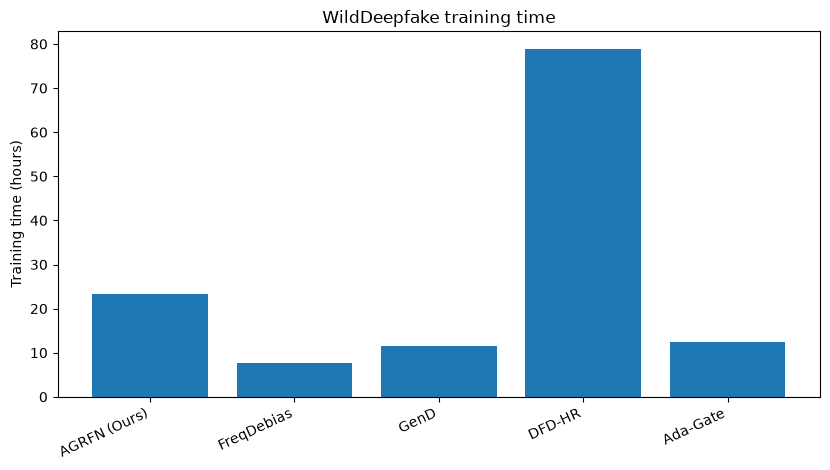

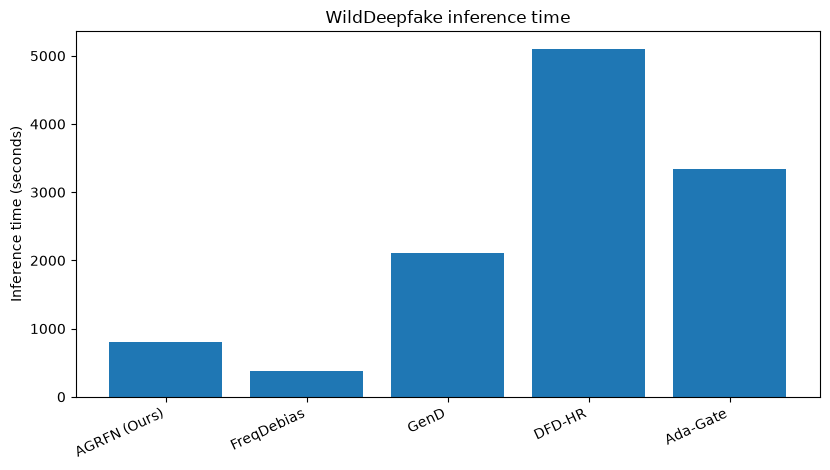

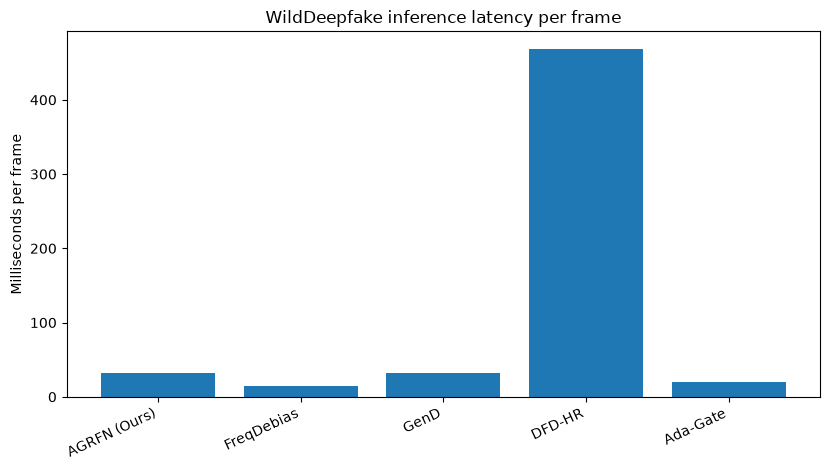

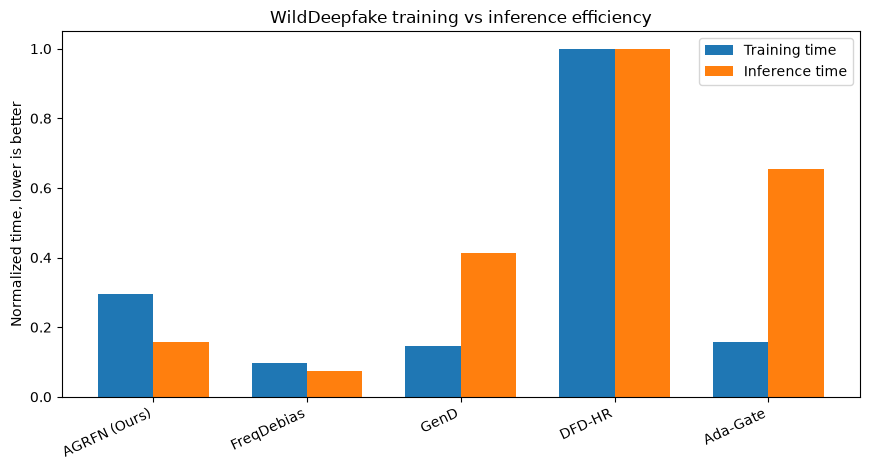


Saved graph files:
Training time PNG: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/wilddeepfake_training_time_corrected.png
Training time PDF: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/wilddeepfake_training_time_corrected.pdf
Inference time PNG: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/wilddeepfake_inference_time_corrected.png
Inference time PDF: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/wilddeepfake_inference_time_corrected.pdf
ms/frame PNG: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/wilddeepfake_ms_per_frame_corrected.png
ms/frame PDF: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/wilddeepfake_ms_per_frame_corrected.pdf
Normalized comparison PNG: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/wilddeepfake_trainin

In [16]:
# ============================================================
# Corrected WildDeepfake computational efficiency table + graphs
#
# Important correction:
#   AGRFN training time uses deduplicated active epoch time = 23.32 h
#   NOT file timestamp span = 246.04 h.
#
# Saves:
#   outputs_computational_efficiency/wilddeepfake_efficiency_corrected.csv
#   outputs_computational_efficiency/wilddeepfake_efficiency_corrected.tex
#   outputs_computational_efficiency/wilddeepfake_training_time_corrected.png/pdf
#   outputs_computational_efficiency/wilddeepfake_inference_time_corrected.png/pdf
#   outputs_computational_efficiency/wilddeepfake_ms_per_frame_corrected.png/pdf
#   outputs_computational_efficiency/wilddeepfake_training_vs_inference_normalized_corrected.png/pdf
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")
OUT_DIR = PROJECT_ROOT / "outputs_computational_efficiency"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_OUT = OUT_DIR / "wilddeepfake_efficiency_corrected.csv"
TEX_OUT = OUT_DIR / "wilddeepfake_efficiency_corrected.tex"

TRAIN_PNG = OUT_DIR / "wilddeepfake_training_time_corrected.png"
TRAIN_PDF = OUT_DIR / "wilddeepfake_training_time_corrected.pdf"

INFER_PNG = OUT_DIR / "wilddeepfake_inference_time_corrected.png"
INFER_PDF = OUT_DIR / "wilddeepfake_inference_time_corrected.pdf"

MS_PNG = OUT_DIR / "wilddeepfake_ms_per_frame_corrected.png"
MS_PDF = OUT_DIR / "wilddeepfake_ms_per_frame_corrected.pdf"

NORM_PNG = OUT_DIR / "wilddeepfake_training_vs_inference_normalized_corrected.png"
NORM_PDF = OUT_DIR / "wilddeepfake_training_vs_inference_normalized_corrected.pdf"

# ------------------------------------------------------------------
# Final corrected values
# ------------------------------------------------------------------
df = pd.DataFrame([
    {
        "Model": "AGRFN (Ours)",
        "Train (h)": 23.32,
        "Infer. (s)": 810.91,
        "ms/frame": 31.44,
        "training_time_source": "deduplicated completed-epoch tqdm logs, idle resume gap excluded",
    },
    {
        "Model": "FreqDebias",
        "Train (h)": 7.65,
        "Infer. (s)": 379.20,
        "ms/frame": 14.70,
        "training_time_source": "estimated from WildDeepfake output timestamps",
    },
    {
        "Model": "GenD",
        "Train (h)": 11.50,
        "Infer. (s)": 2107.10,
        "ms/frame": 32.45,
        "training_time_source": "estimated from WildDeepfake output timestamps",
    },
    {
        "Model": "DFD-HR",
        "Train (h)": 78.92,
        "Infer. (s)": 5103.92,
        "ms/frame": 468.87,
        "training_time_source": "recorded or previously recovered from saved artifacts",
    },
    {
        "Model": "Ada-Gate",
        "Train (h)": 12.40,
        "Infer. (s)": 3344.94,
        "ms/frame": 20.19,
        "training_time_source": "recorded or previously recovered from saved artifacts",
    },
])

df.to_csv(CSV_OUT, index=False)

print("=" * 100)
print("Corrected WildDeepfake computational efficiency table")
print("=" * 100)
display(df)

print("Saved CSV:", CSV_OUT)

# ------------------------------------------------------------------
# LaTeX table
# ------------------------------------------------------------------
def fmt(x):
    return f"{float(x):.2f}"

lines = []
lines.append(r"\begin{table}[t]")
lines.append(r"\caption{Computational efficiency on WildDeepfake. Training time denotes active wall-clock duration; for AGRFN, idle time between stopped and resumed runs is excluded using deduplicated epoch logs.}")
lines.append(r"\centering")
lines.append(r"\fontsize{9}{11}\selectfont")
lines.append(r"\setlength{\tabcolsep}{5pt}")
lines.append(r"\renewcommand{\arraystretch}{1.05}")
lines.append("")
lines.append(r"\begin{tabular}{|l|r|r|r|}")
lines.append(r"\hline")
lines.append(r"Model &")
lines.append(r"Train (h) &")
lines.append(r"Infer. (s) &")
lines.append(r"ms/frame \\")
lines.append(r"\hline")

for _, row in df.iterrows():
    lines.append("")
    lines.append(row["Model"])
    lines.append("&")
    lines.append(fmt(row["Train (h)"]))
    lines.append("&")
    lines.append(fmt(row["Infer. (s)"]))
    lines.append("&")
    lines.append(fmt(row["ms/frame"]) + r" \\")

lines.append("")
lines.append(r"\hline")
lines.append(r"\end{tabular}")
lines.append(r"\end{table}")

latex = "\n".join(lines)
TEX_OUT.write_text(latex)

print("\nSaved LaTeX:", TEX_OUT)
print("\nLaTeX:")
print(latex)

# ------------------------------------------------------------------
# Graph 1: Training time
# ------------------------------------------------------------------
x = np.arange(len(df))

plt.figure(figsize=(8.4, 4.8))
plt.bar(x, df["Train (h)"])
plt.xticks(x, df["Model"], rotation=25, ha="right")
plt.ylabel("Training time (hours)")
plt.title("WildDeepfake training time")
plt.tight_layout()
plt.savefig(TRAIN_PNG, dpi=300, bbox_inches="tight")
plt.savefig(TRAIN_PDF, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# Graph 2: Inference time
# ------------------------------------------------------------------
plt.figure(figsize=(8.4, 4.8))
plt.bar(x, df["Infer. (s)"])
plt.xticks(x, df["Model"], rotation=25, ha="right")
plt.ylabel("Inference time (seconds)")
plt.title("WildDeepfake inference time")
plt.tight_layout()
plt.savefig(INFER_PNG, dpi=300, bbox_inches="tight")
plt.savefig(INFER_PDF, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# Graph 3: ms/frame
# ------------------------------------------------------------------
plt.figure(figsize=(8.4, 4.8))
plt.bar(x, df["ms/frame"])
plt.xticks(x, df["Model"], rotation=25, ha="right")
plt.ylabel("Milliseconds per frame")
plt.title("WildDeepfake inference latency per frame")
plt.tight_layout()
plt.savefig(MS_PNG, dpi=300, bbox_inches="tight")
plt.savefig(MS_PDF, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# Graph 4: Normalized training vs inference
# This is best for comparing both on one plot because hours and seconds
# are different units.
# ------------------------------------------------------------------
norm_df = df.copy()
norm_df["Training time"] = norm_df["Train (h)"] / norm_df["Train (h)"].max()
norm_df["Inference time"] = norm_df["Infer. (s)"] / norm_df["Infer. (s)"].max()

bar_w = 0.36

plt.figure(figsize=(8.8, 4.8))
plt.bar(x - bar_w / 2, norm_df["Training time"], width=bar_w, label="Training time")
plt.bar(x + bar_w / 2, norm_df["Inference time"], width=bar_w, label="Inference time")
plt.xticks(x, norm_df["Model"], rotation=25, ha="right")
plt.ylabel("Normalized time, lower is better")
plt.title("WildDeepfake training vs inference efficiency")
plt.legend()
plt.tight_layout()
plt.savefig(NORM_PNG, dpi=300, bbox_inches="tight")
plt.savefig(NORM_PDF, bbox_inches="tight")
plt.show()

print("\nSaved graph files:")
print("Training time PNG:", TRAIN_PNG)
print("Training time PDF:", TRAIN_PDF)
print("Inference time PNG:", INFER_PNG)
print("Inference time PDF:", INFER_PDF)
print("ms/frame PNG:", MS_PNG)
print("ms/frame PDF:", MS_PDF)
print("Normalized comparison PNG:", NORM_PNG)
print("Normalized comparison PDF:", NORM_PDF)

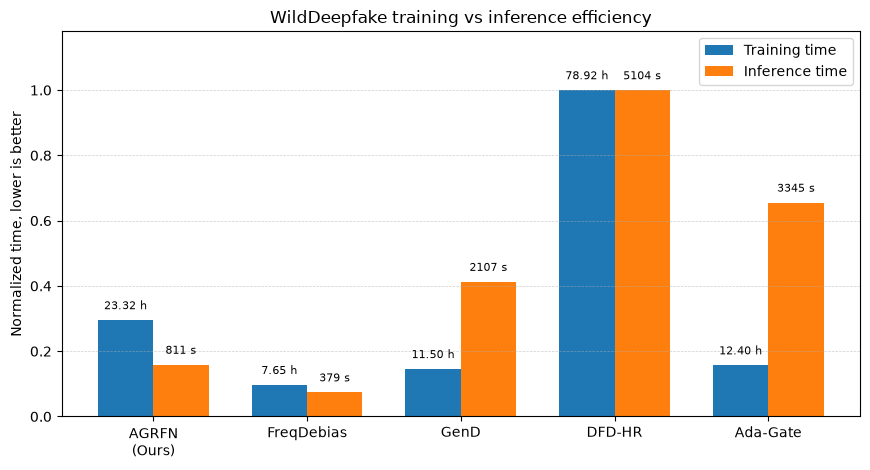

Saved CSV: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/wilddeepfake_training_vs_inference_with_labels.csv
Saved PNG: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/wilddeepfake_training_vs_inference_with_labels.png
Saved PDF: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/wilddeepfake_training_vs_inference_with_labels.pdf


In [17]:
# ============================================================
# WildDeepfake training vs inference graph
# One combined normalized bar chart with values on top
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")
OUT_DIR = PROJECT_ROOT / "outputs_computational_efficiency"
OUT_DIR.mkdir(parents=True, exist_ok=True)

PNG_OUT = OUT_DIR / "wilddeepfake_training_vs_inference_with_labels.png"
PDF_OUT = OUT_DIR / "wilddeepfake_training_vs_inference_with_labels.pdf"
CSV_OUT = OUT_DIR / "wilddeepfake_training_vs_inference_with_labels.csv"

# Corrected WildDeepfake efficiency values
df = pd.DataFrame([
    {"Model": "AGRFN\n(Ours)", "Train (h)": 23.32, "Infer. (s)": 810.91},
    {"Model": "FreqDebias", "Train (h)": 7.65, "Infer. (s)": 379.20},
    {"Model": "GenD", "Train (h)": 11.50, "Infer. (s)": 2107.10},
    {"Model": "DFD-HR", "Train (h)": 78.92, "Infer. (s)": 5103.92},
    {"Model": "Ada-Gate", "Train (h)": 12.40, "Infer. (s)": 3344.94},
])

# Normalize so training hours and inference seconds can be shown on one axis.
df["Training time"] = df["Train (h)"] / df["Train (h)"].max()
df["Inference time"] = df["Infer. (s)"] / df["Infer. (s)"].max()

df.to_csv(CSV_OUT, index=False)

x = np.arange(len(df))
bar_w = 0.36

fig, ax = plt.subplots(figsize=(8.8, 4.8))

bars_train = ax.bar(
    x - bar_w / 2,
    df["Training time"],
    width=bar_w,
    label="Training time"
)

bars_infer = ax.bar(
    x + bar_w / 2,
    df["Inference time"],
    width=bar_w,
    label="Inference time"
)

# Add real values on top of bars.
for bar, value in zip(bars_train, df["Train (h)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.025,
        f"{value:.2f} h",
        ha="center",
        va="bottom",
        fontsize=8,
        rotation=0,
    )

for bar, value in zip(bars_infer, df["Infer. (s)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.025,
        f"{value:.0f} s",
        ha="center",
        va="bottom",
        fontsize=8,
        rotation=0,
    )

ax.set_xticks(x)
ax.set_xticklabels(df["Model"])
ax.set_ylabel("Normalized time, lower is better")
ax.set_title("WildDeepfake training vs inference efficiency")
ax.set_ylim(0, 1.18)
ax.legend()

ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.6)

plt.tight_layout()
plt.savefig(PNG_OUT, dpi=300, bbox_inches="tight")
plt.savefig(PDF_OUT, bbox_inches="tight")
plt.show()

print("Saved CSV:", CSV_OUT)
print("Saved PNG:", PNG_OUT)
print("Saved PDF:", PDF_OUT)

In [15]:
# ============================================================
# Correct AGRFN WildDeepfake active training time estimate
# Deduplicates repeated tqdm lines by epoch number.
# ============================================================

from pathlib import Path
import re
import pandas as pd
import numpy as np

PROJECT_ROOT = Path("/home/jovyan/Deepfake_Low Resource_Low Resolution")

AGR_DIR = PROJECT_ROOT / "outputs_agrfn_wilddeepfake_ablation/E3_adaptive_film"
OUT_DIR = PROJECT_ROOT / "outputs_computational_efficiency"
OUT_DIR.mkdir(parents=True, exist_ok=True)

AUDIT_CSV = OUT_DIR / "agrfn_wilddeepfake_epoch_time_dedup_audit.csv"
SUMMARY_CSV = OUT_DIR / "agrfn_wilddeepfake_epoch_time_dedup_summary.csv"

def parse_elapsed_to_seconds(s):
    parts = [int(x) for x in s.split(":")]
    if len(parts) == 2:
        return parts[0] * 60 + parts[1]
    if len(parts) == 3:
        return parts[0] * 3600 + parts[1] * 60 + parts[2]
    return None

rows = []

for p in list(AGR_DIR.rglob("*.log")) + list(AGR_DIR.rglob("*.txt")):
    if ".ipynb_checkpoints" in str(p):
        continue

    text = p.read_text(errors="replace")

    for line_no, line in enumerate(text.splitlines(), start=1):
        if "Train epoch" not in line or "100%" not in line:
            continue

        # Example:
        # Train epoch 11: 100%|...| 11714/11714 [1:31:20<00:00, ...]
        m_epoch = re.search(r"Train epoch\s+(\d+)", line)
        m_elapsed = re.search(r"\[([0-9]{1,3}:[0-9]{2}(?::[0-9]{2})?)<", line)

        if not m_epoch or not m_elapsed:
            continue

        epoch = int(m_epoch.group(1))
        elapsed_str = m_elapsed.group(1)
        elapsed_sec = parse_elapsed_to_seconds(elapsed_str)

        if elapsed_sec is None:
            continue

        rows.append({
            "source_file": str(p),
            "line_no": line_no,
            "epoch": epoch,
            "elapsed_str": elapsed_str,
            "elapsed_sec": elapsed_sec,
            "elapsed_min": elapsed_sec / 60.0,
            "elapsed_h": elapsed_sec / 3600.0,
            "line_preview": line[:300],
        })

audit = pd.DataFrame(rows)

print("=" * 100)
print("Raw completed epoch lines")
print("=" * 100)
print("Raw completed tqdm lines found:", len(audit))

if len(audit) == 0:
    raise RuntimeError("No completed Train epoch 100% tqdm lines found.")

print("\nRaw duplicate counts by epoch:")
dup_counts = audit.groupby("epoch").size().reset_index(name="count")
display(dup_counts)

print("\nRaw elapsed values by epoch:")
display(
    audit.groupby("epoch")["elapsed_min"]
    .agg(["count", "min", "median", "max"])
    .reset_index()
)

# ------------------------------------------------------------------
# Dedup strategy:
# For each epoch, use the median completed elapsed time.
# Why median? If the same completed bar is repeated many times, median is stable.
# ------------------------------------------------------------------
dedup = (
    audit.groupby("epoch")
    .agg(
        duplicate_lines=("elapsed_sec", "size"),
        elapsed_sec_median=("elapsed_sec", "median"),
        elapsed_sec_min=("elapsed_sec", "min"),
        elapsed_sec_max=("elapsed_sec", "max"),
        source_files=("source_file", lambda x: " | ".join(sorted(set(x)))),
    )
    .reset_index()
    .sort_values("epoch")
)

dedup["elapsed_h_median"] = dedup["elapsed_sec_median"] / 3600.0
dedup["elapsed_min_median"] = dedup["elapsed_sec_median"] / 60.0

# Sanity check: remove impossible epochs if a stale log has hundreds of epoch numbers.
# For your AGRFN paper run, expected epochs should be small, usually <= 20.
# Keep all unique epochs for now, but display them.
total_active_h = dedup["elapsed_h_median"].sum()

audit.to_csv(AUDIT_CSV, index=False)
dedup.to_csv(SUMMARY_CSV, index=False)

print("\n" + "=" * 100)
print("Deduplicated AGRFN epoch-time summary")
print("=" * 100)
display(dedup)

print(f"\nUnique completed epochs counted: {len(dedup)}")
print(f"Estimated active training time after deduplication: {total_active_h:.2f} h")
print(f"Average time per completed epoch: {dedup['elapsed_min_median'].mean():.2f} min")

print("\nSaved raw audit:", AUDIT_CSV)
print("Saved dedup summary:", SUMMARY_CSV)

Raw completed epoch lines
Raw completed tqdm lines found: 914

Raw duplicate counts by epoch:


,epoch,count
0,1,58
1,2,64
2,3,64
3,4,62
4,5,56
5,6,63
6,7,56
7,8,64
8,9,59
9,10,57



Raw elapsed values by epoch:


,epoch,count,min,median,max
0,1,58,78.050000,78.241667,78.433333
1,2,64,76.333333,76.516667,76.700000
2,3,64,83.400000,83.650000,83.916667
3,4,62,86.100000,86.316667,86.533333
4,5,56,96.383333,96.600000,96.783333
5,6,63,84.683333,84.900000,85.150000
6,7,56,88.366667,88.575000,88.733333
7,8,64,82.183333,82.366667,82.550000
8,9,59,84.800000,85.000000,85.216667
9,10,57,84.200000,84.400000,84.566667



Deduplicated AGRFN epoch-time summary


,epoch,duplicate_lines,elapsed_sec_median,elapsed_sec_min,elapsed_sec_max,source_files,elapsed_h_median,elapsed_min_median
0,1,58,4694.5,4683,4706,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1.304028,78.241667
1,2,64,4591.0,4580,4602,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1.275278,76.516667
2,3,64,5019.0,5004,5035,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1.394167,83.650000
3,4,62,5179.0,5166,5192,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1.438611,86.316667
4,5,56,5796.0,5783,5807,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1.610000,96.600000
5,6,63,5094.0,5081,5109,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1.415000,84.900000
6,7,56,5314.5,5302,5324,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1.476250,88.575000
7,8,64,4942.0,4931,4953,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1.372778,82.366667
8,9,59,5100.0,5088,5113,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1.416667,85.000000
9,10,57,5064.0,5052,5074,/home/jovyan/Deepfake_Low Resource_Low Resolut...,1.406667,84.400000



Unique completed epochs counted: 15
Estimated active training time after deduplication: 23.32 h
Average time per completed epoch: 93.26 min

Saved raw audit: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/agrfn_wilddeepfake_epoch_time_dedup_audit.csv
Saved dedup summary: /home/jovyan/Deepfake_Low Resource_Low Resolution/outputs_computational_efficiency/agrfn_wilddeepfake_epoch_time_dedup_summary.csv
